# 9bp (intravoxel / acquisition-noise runs) on Sim2: a few examples

Real Sim2 and forward-simulated Sim2 fields, shown with the user's own `imagesc3d2` (grey, sagittal / coronal / axial, same rotation `[90, 90, 90]` as the Sim2 cells of the paper notebook).
Each figure = one volume; order inside a block: truth, `dirty` (the input), `noise_clean` (reference), `iv_noisestat`, `iv_full`.
eNDI = ndiCG, alpha 1e-5, **25 fixed iterations**, 256^3 padding, NRMSE inside the brain mask in the title.

**Reading guide (CLAUDE.md 9bp-bis, single seed, one volume):** the runs did NOT beat `noise_clean` on real Sim2 (48.28 / 48.37 vs 47.31 at 25 iterations).
The calcification blocks are the interesting ones: the shell field is still not in the input.

Data: `runs/iv_views.npz` (made on the server by `scripts/export_iv_views.py`). It holds the three planes through two points (brain centre, calcification
centre), not whole volumes; the cell below puts them back into zero volumes so that `imagesc3d2` (which cuts volumes at `pos`) shows exactly those planes.

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

here = [Path.cwd(), *Path.cwd().parents]
def find(*rel):
    for base in here:
        for r in rel:
            if (base / r).exists():
                return base / r
    raise FileNotFoundError(f"none of {rel} found from {Path.cwd()} or its parents")
sys.path.insert(0, str(find("external/FANSI_tools.py", "utils/FANSI_tools.py", "FANSI_tools.py").parent))
from FANSI_tools import imagesc3d2               # the user's own plotting function

Z = np.load(find("runs/iv_views.npz"))
METHODS = ["dirty", "noise_clean", "iv_noisestat", "iv_full"]
LABEL = {"real": "real Sim2", "sim2_snrcal": "forward, SNR-cal noise", "sim2_jumps": "forward, noise + phase jumps", "sim2_snr40": "forward, SNR 40"}
ROT = [90, 90, 90]                               # Sim2 views of the paper notebook
CHI, FIELD = [-0.1, 0.1], [-0.03, 0.03]          # ppm, as in the paper notebook
SCALE = [-0.12, 0.12, -0.12, 0.12]
SHAPE = (Z["mask/centre/axi"].shape[0], Z["mask/centre/axi"].shape[1], Z["mask/centre/sag"].shape[1])
print("volume shape", SHAPE, " points (voxels):", Z["points"].round(1).tolist())

def planes_to_volume(prefix, point):
    # the three stored planes put back at their position; everything else 0; masked to the brain like the paper views
    p = [int(v) for v in Z["points"][0 if point == "centre" else 1]]
    vol = np.zeros(SHAPE, np.float32)
    m = lambda pl: Z[f"mask/{point}/{pl}"].astype(np.float32)
    g = lambda pl: Z[f"{prefix}/{point}/{pl}"].astype(np.float32) * m(pl)
    vol[p[0]] = g("sag")
    vol[:, p[1]] = g("cor")
    vol[:, :, p[2]] = g("axi")
    return vol, tuple(p)

def block(kind, point, sets, contrast, name):
    for sname in sets:
        entries = [("truth", "chi_true" if kind == "chi" else "field_true")] + [(m, f"{kind}/{sname}/{m}") for m in METHODS]
        for m, prefix in entries:
            vol, pos = planes_to_volume(prefix, point)
            e = "" if m == "truth" or kind != "chi" else f"  eNDI@25 {float(Z[f'nrmse/{sname}/{m}']):.2f}%"
            imagesc3d2(vol, pos, cmap="grey", contrast=contrast, fig_num=2, rot_deg=ROT, scale_fig=SCALE, avg_size=0,
                       title_fig=f"{LABEL[sname]}: {m}{e}")

volume shape (164, 205, 205)  points (voxels): [[83.2, 91.2, 105.1], [82.5, 93.5, 147.4]]


## 1. Susceptibility after 25 eNDI iterations (ppm), planes through the brain centre

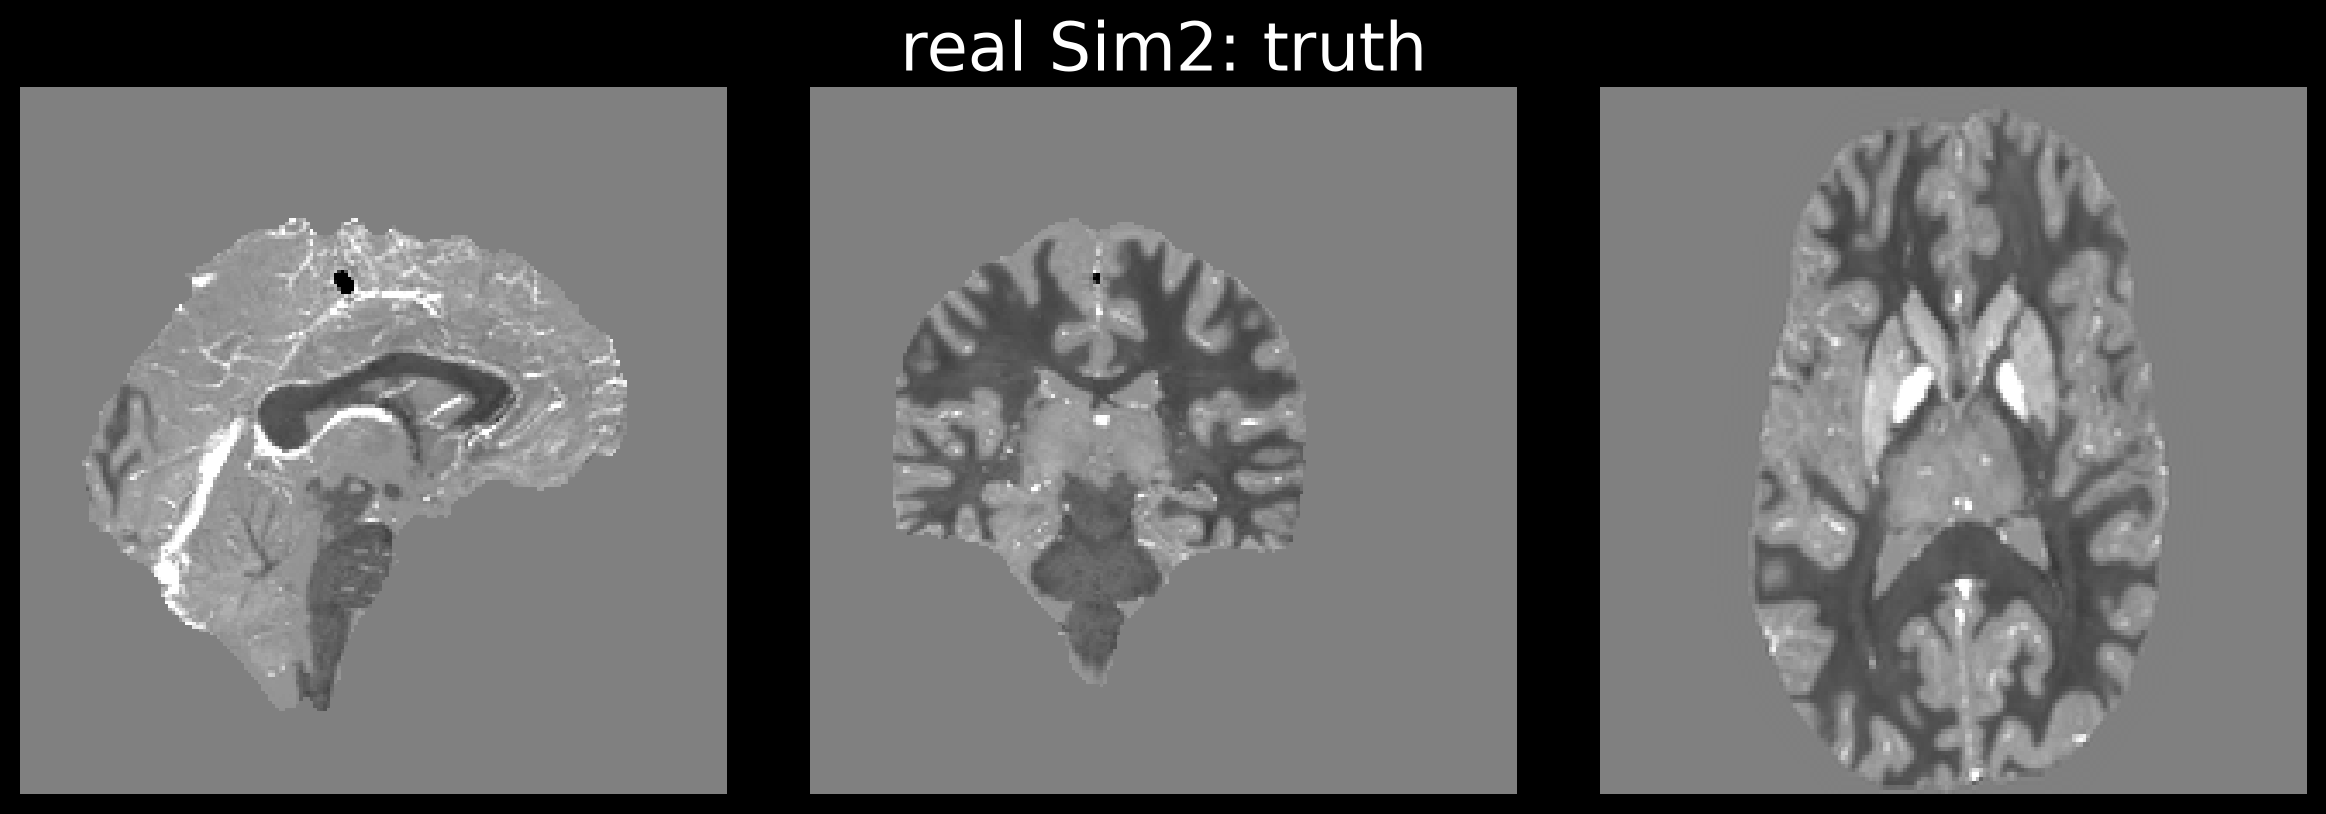

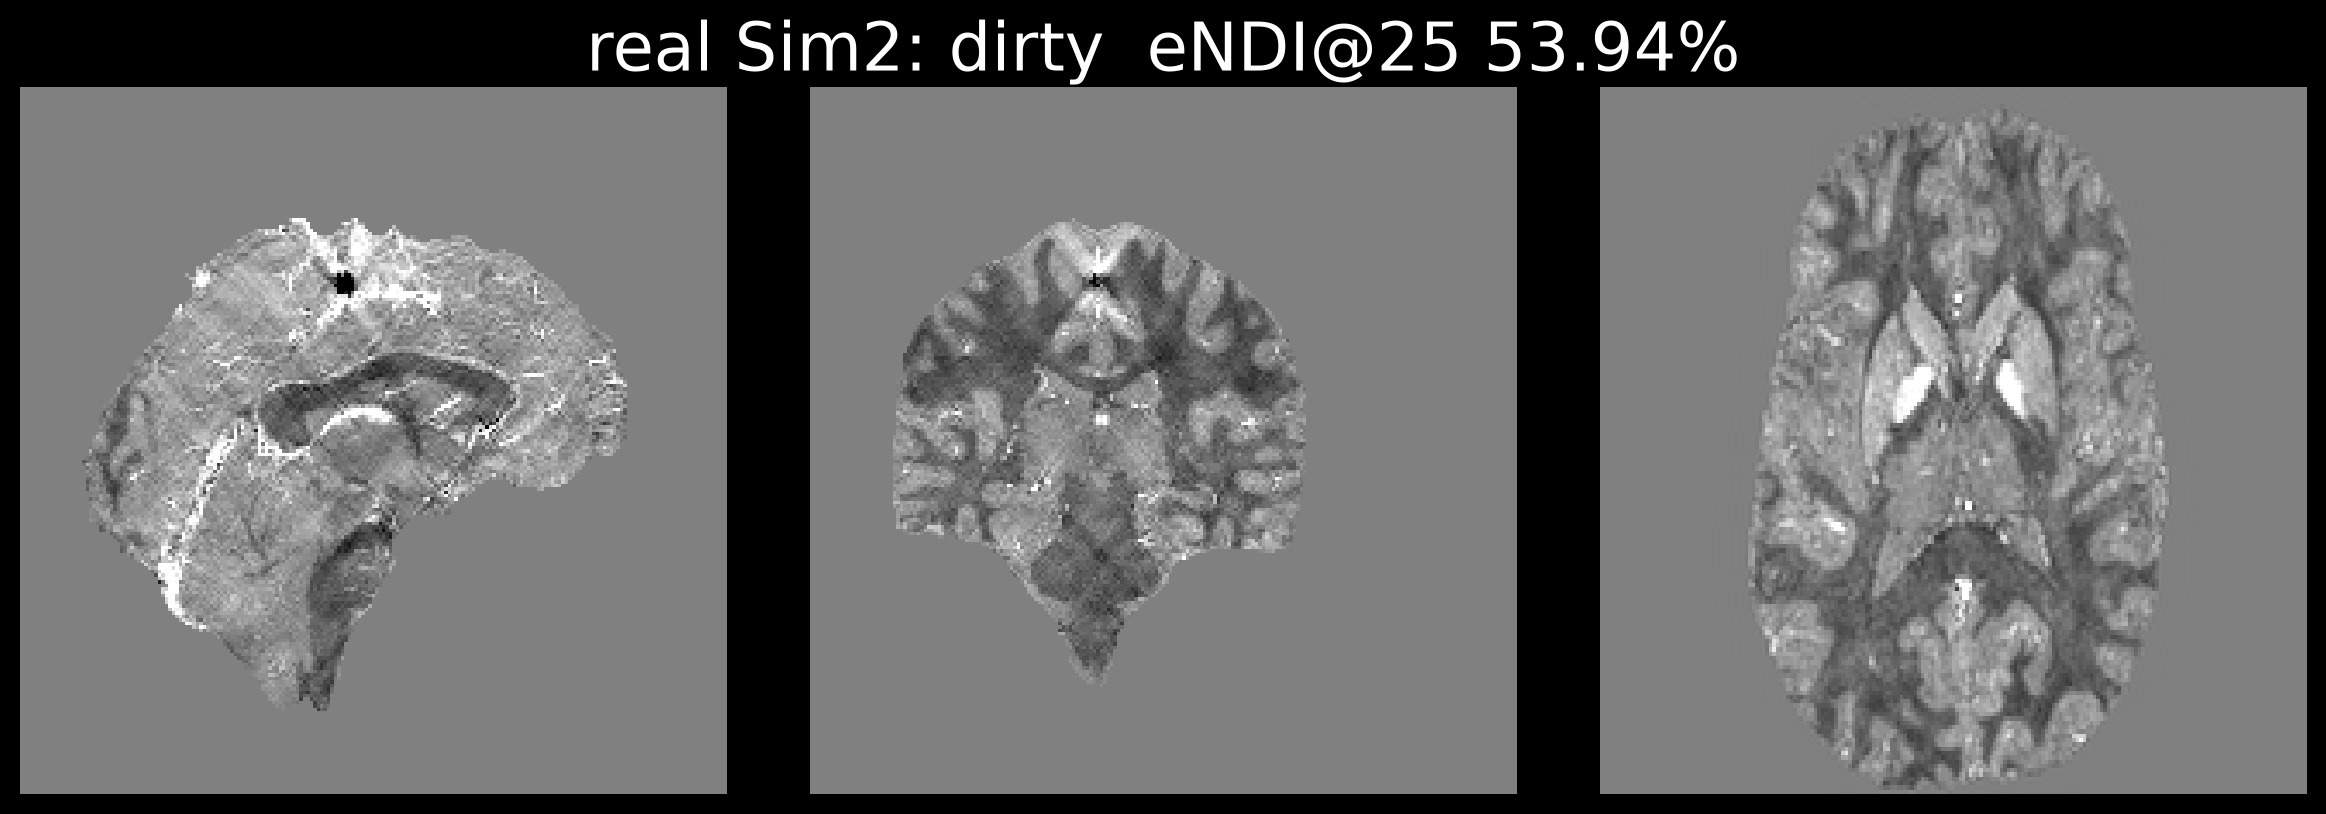

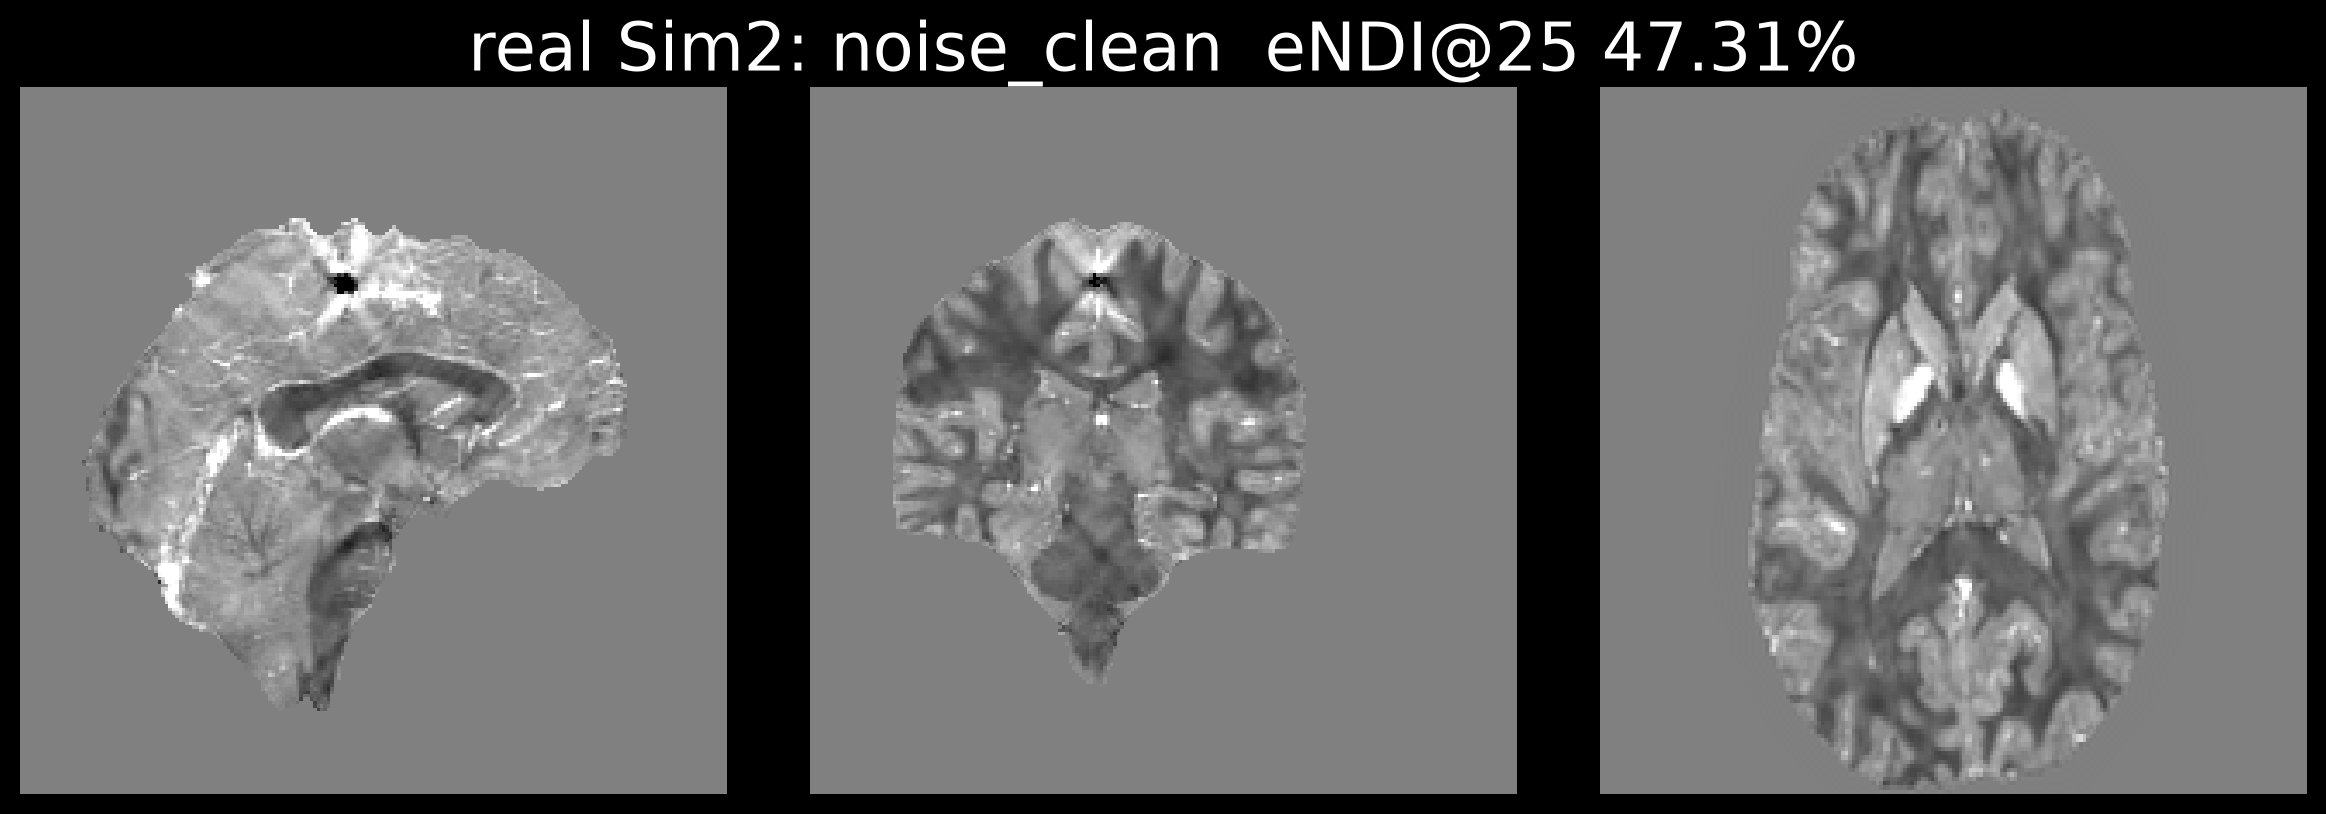

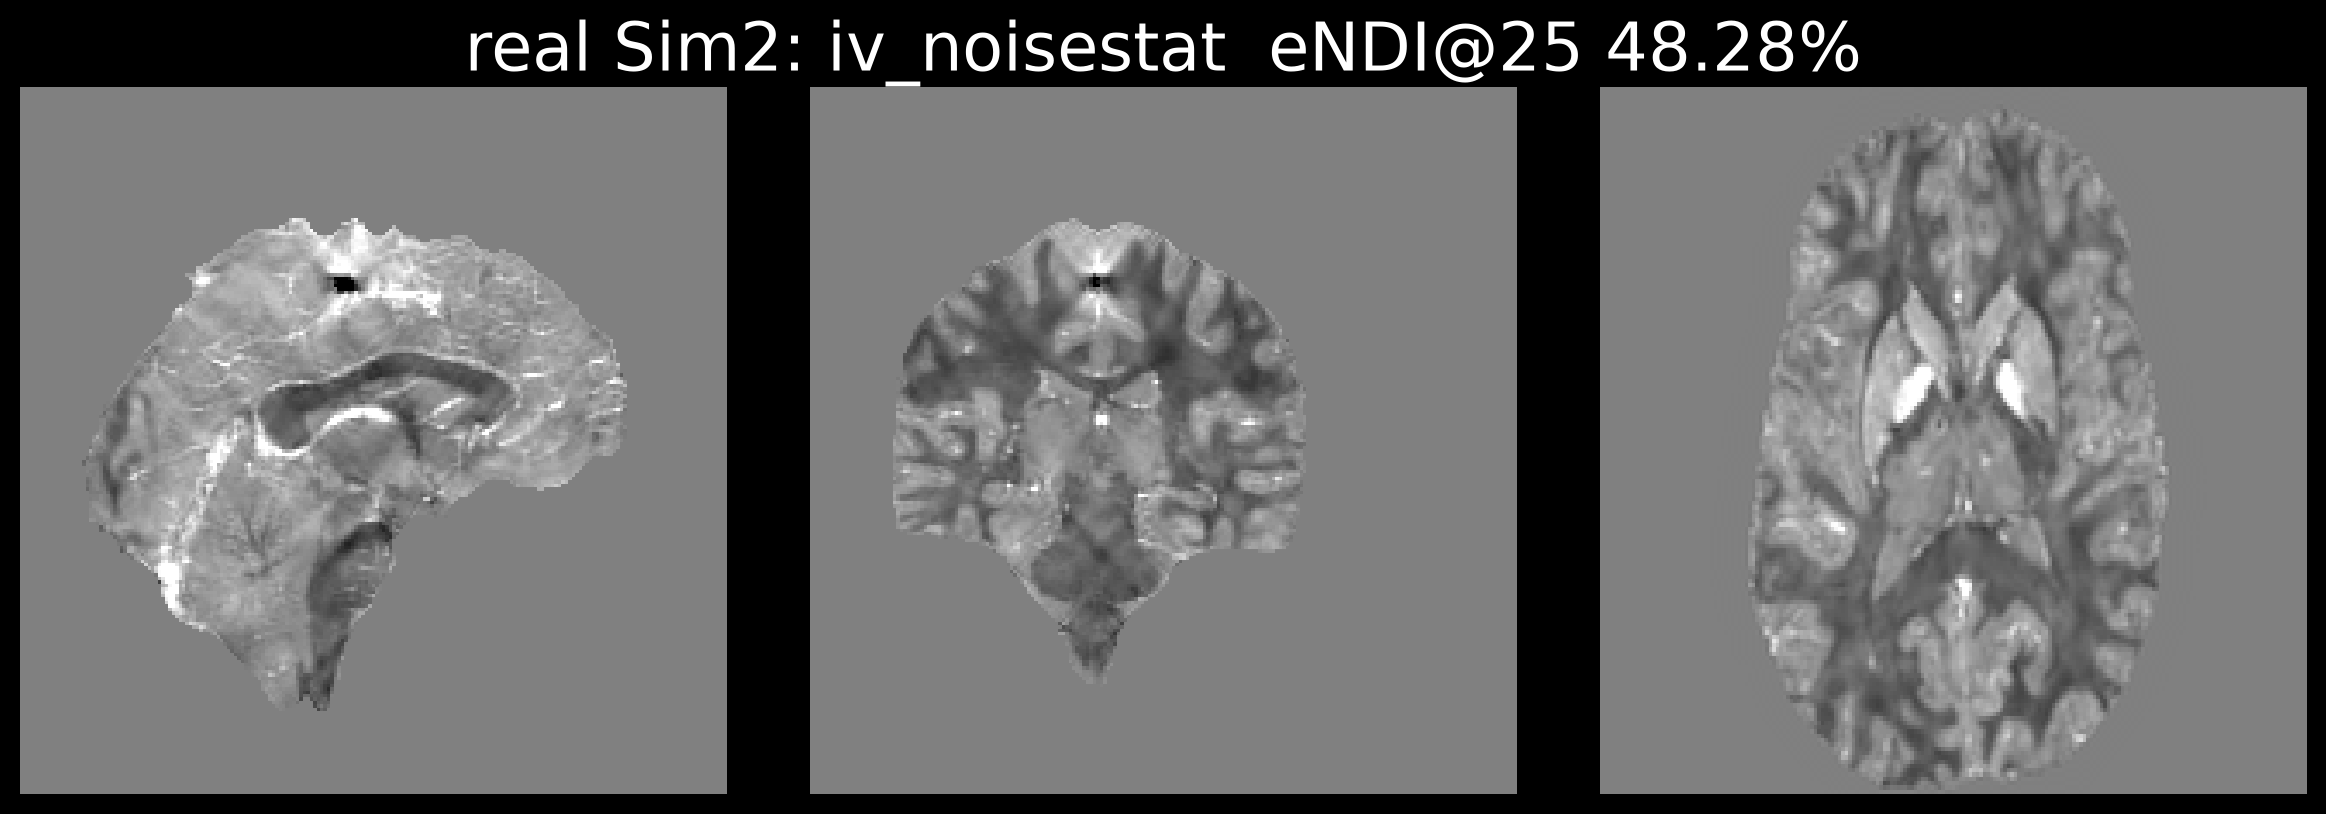

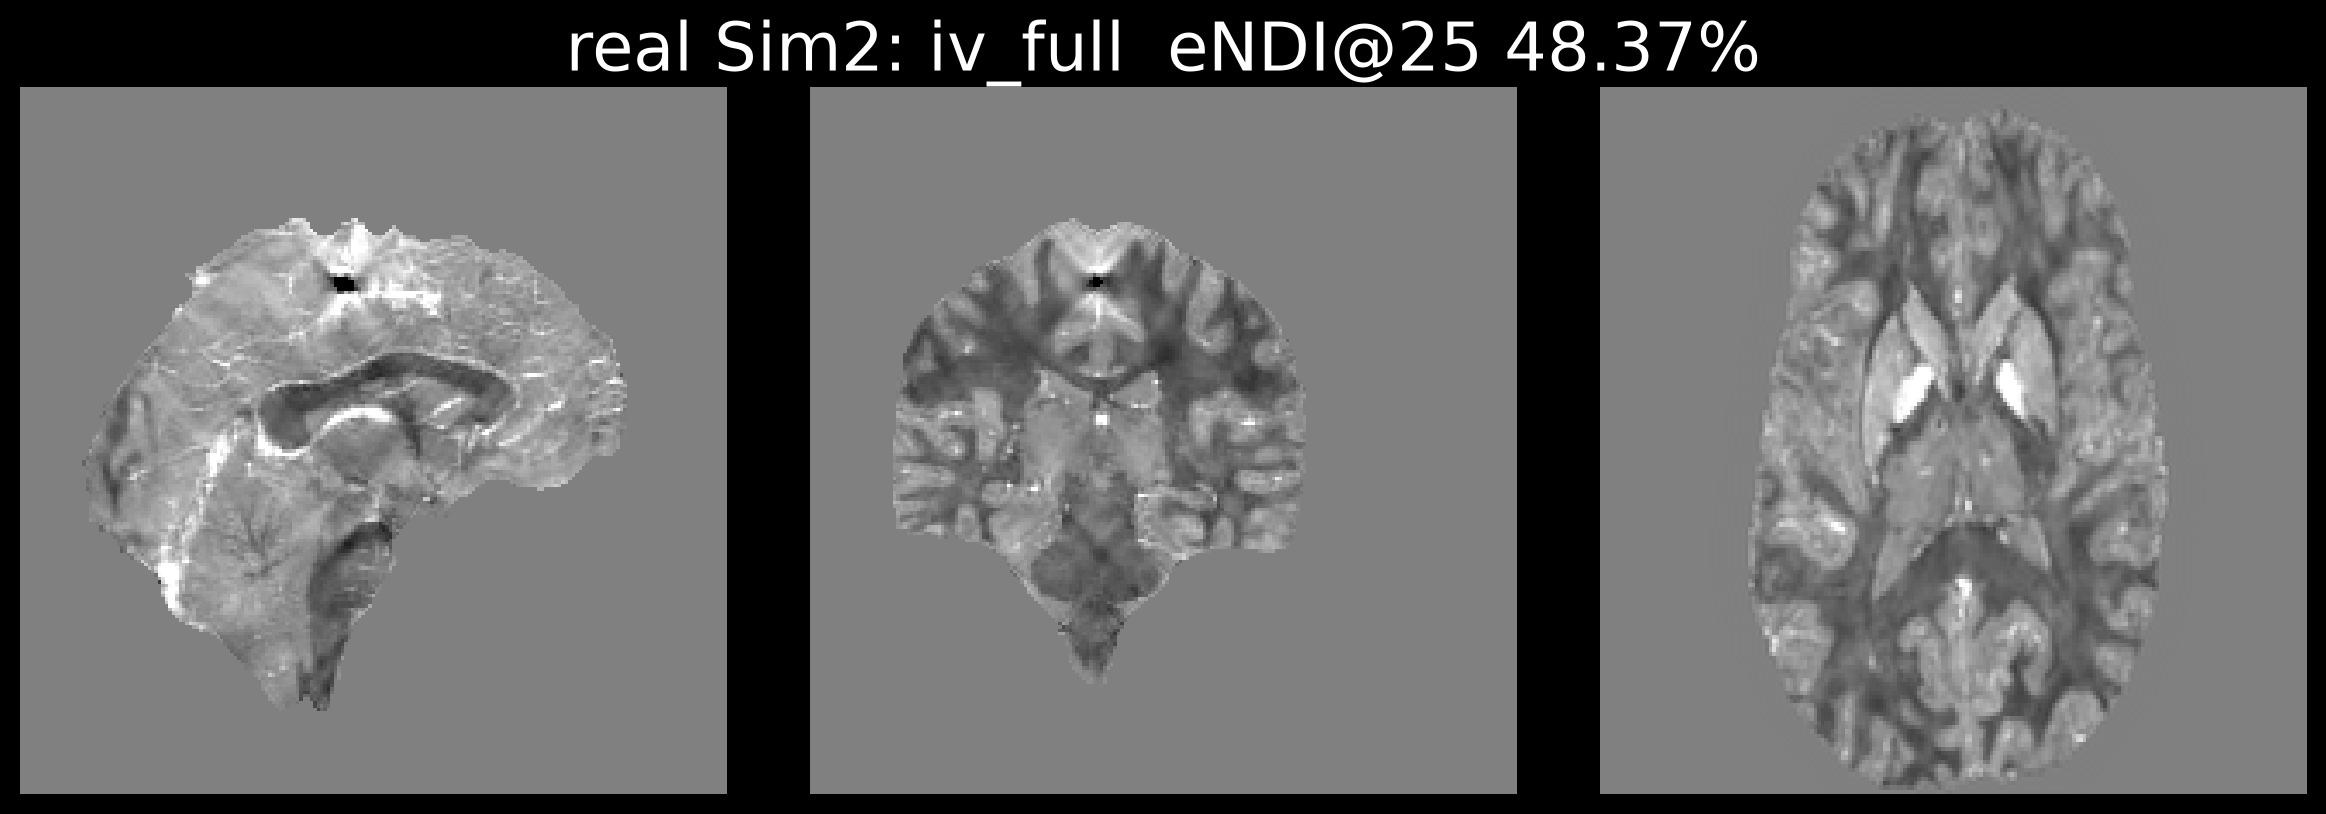

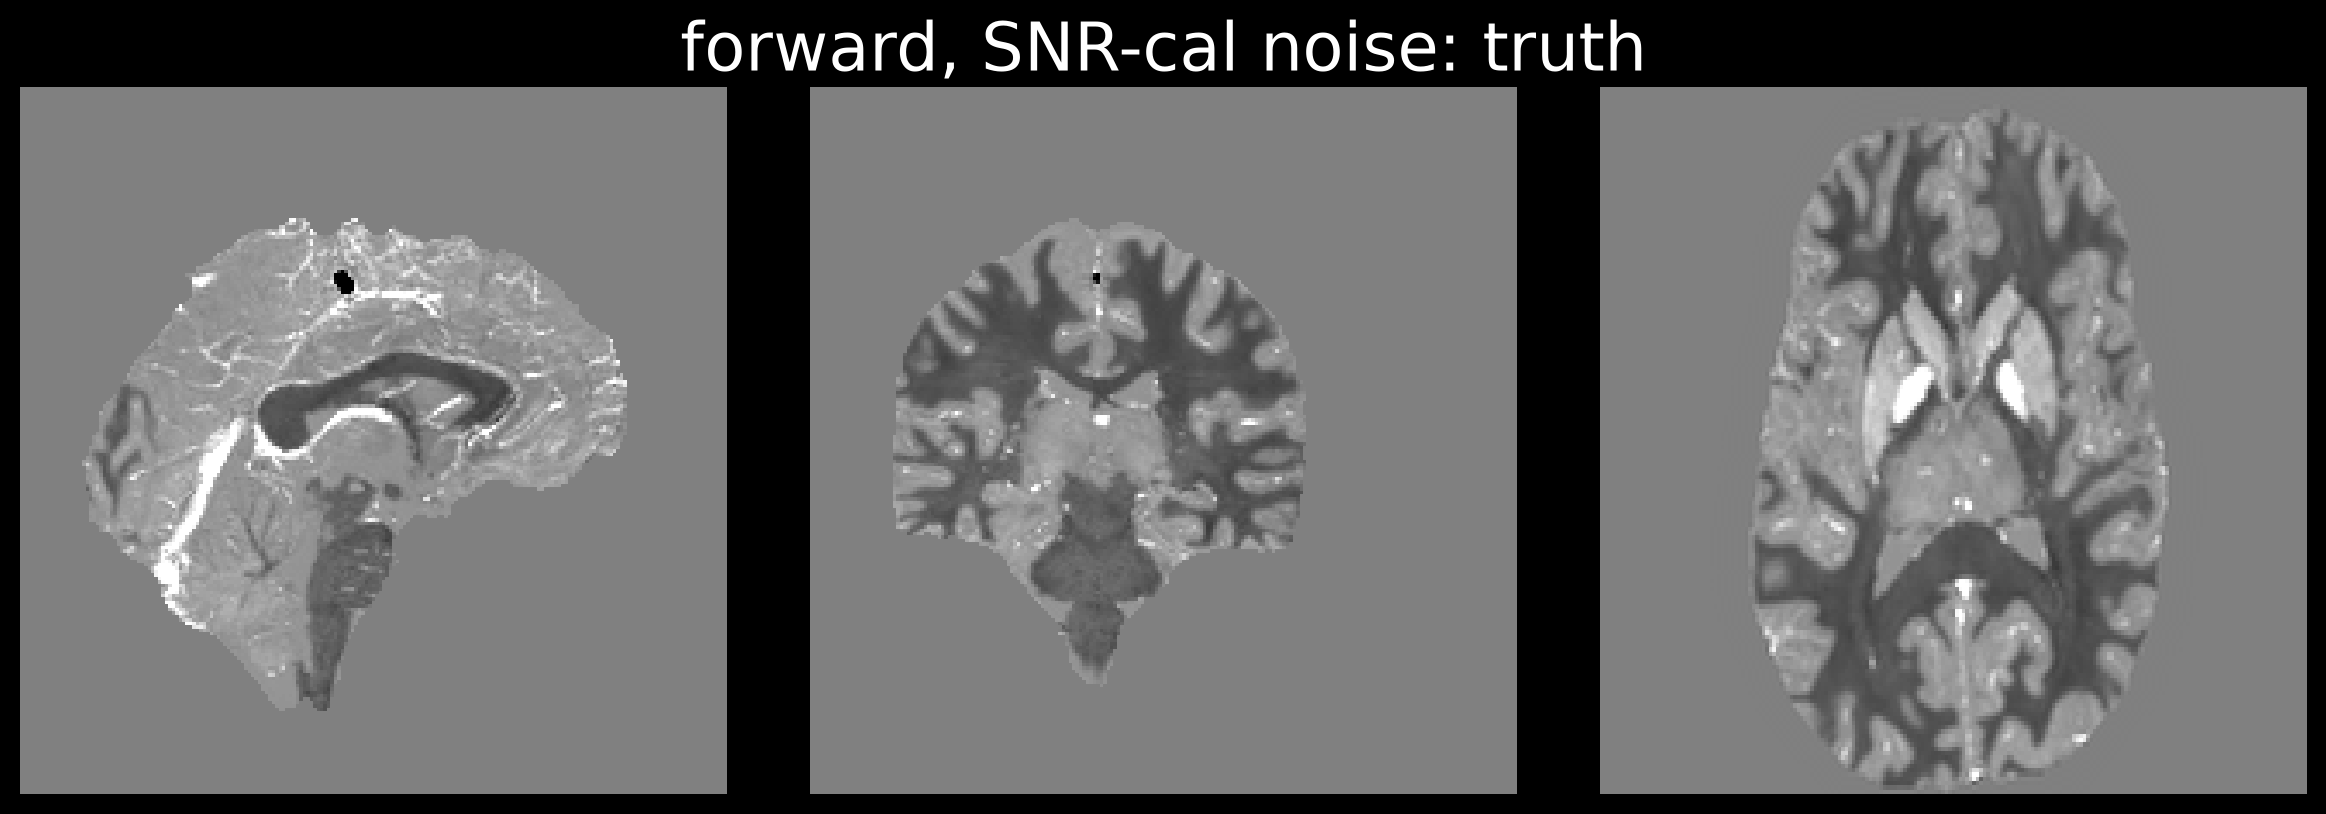

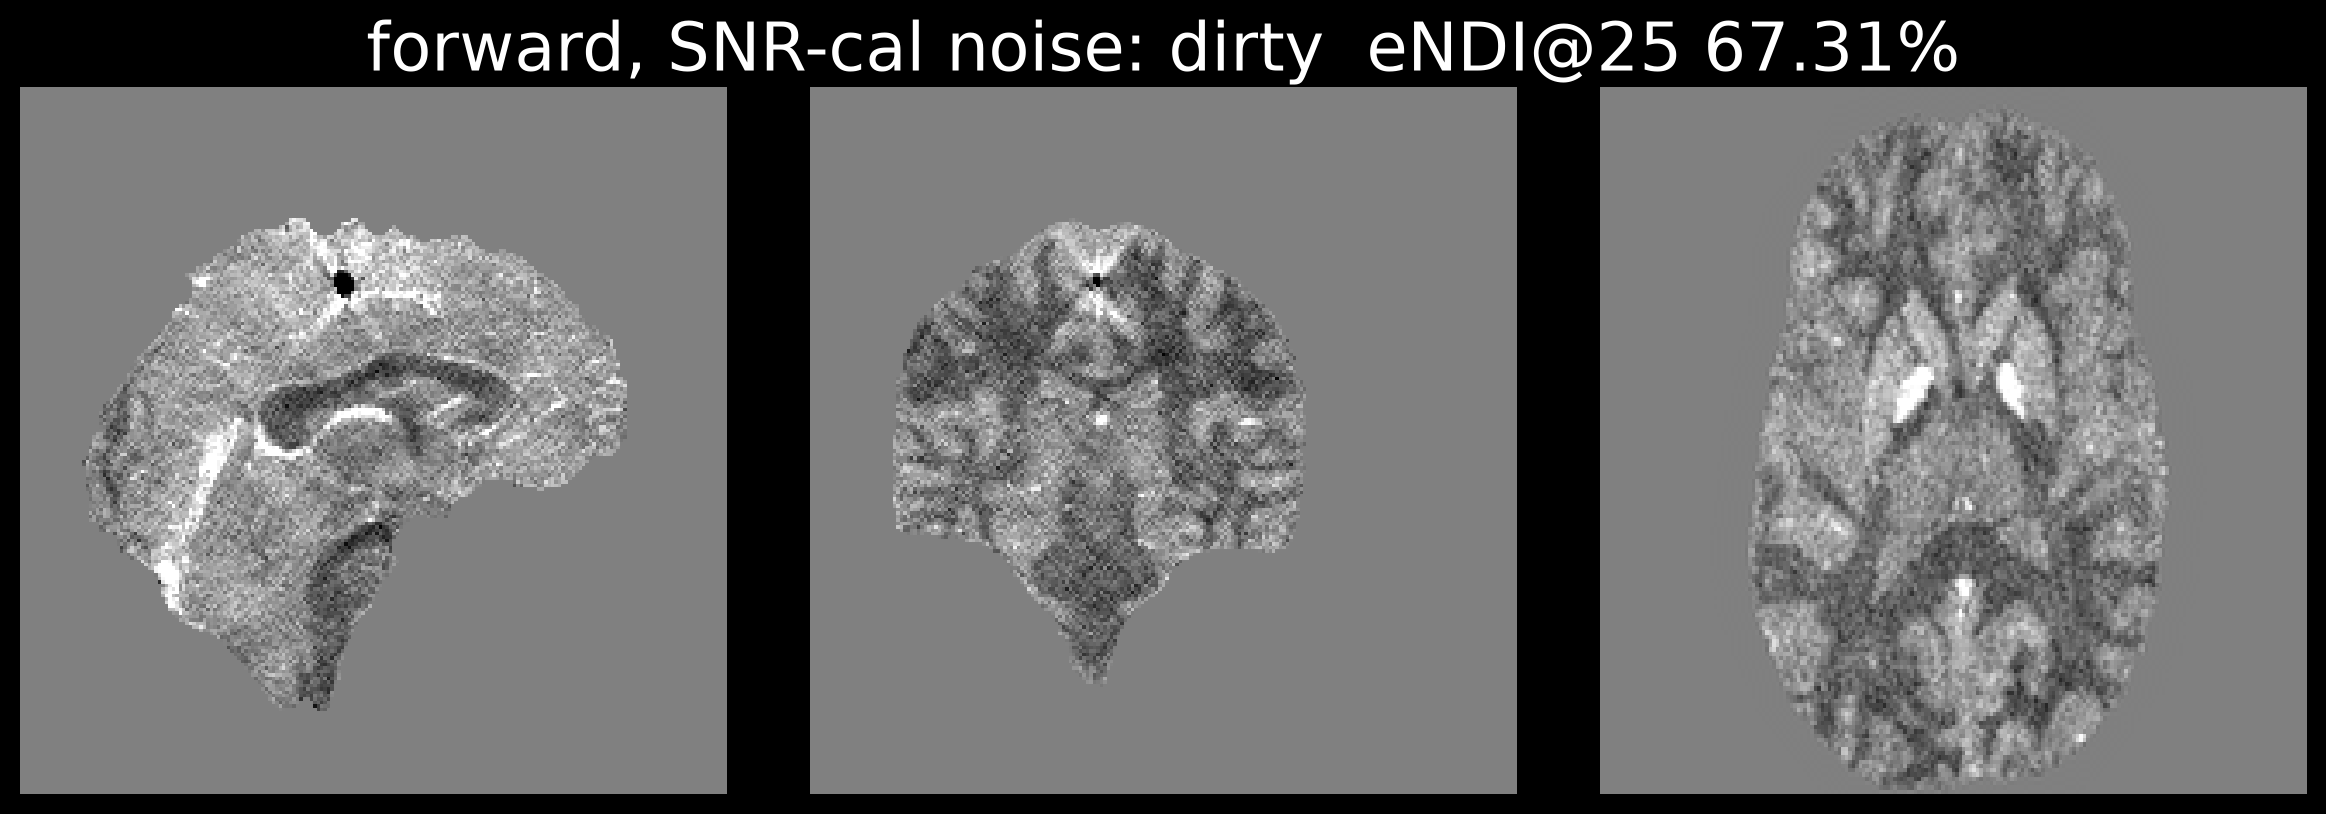

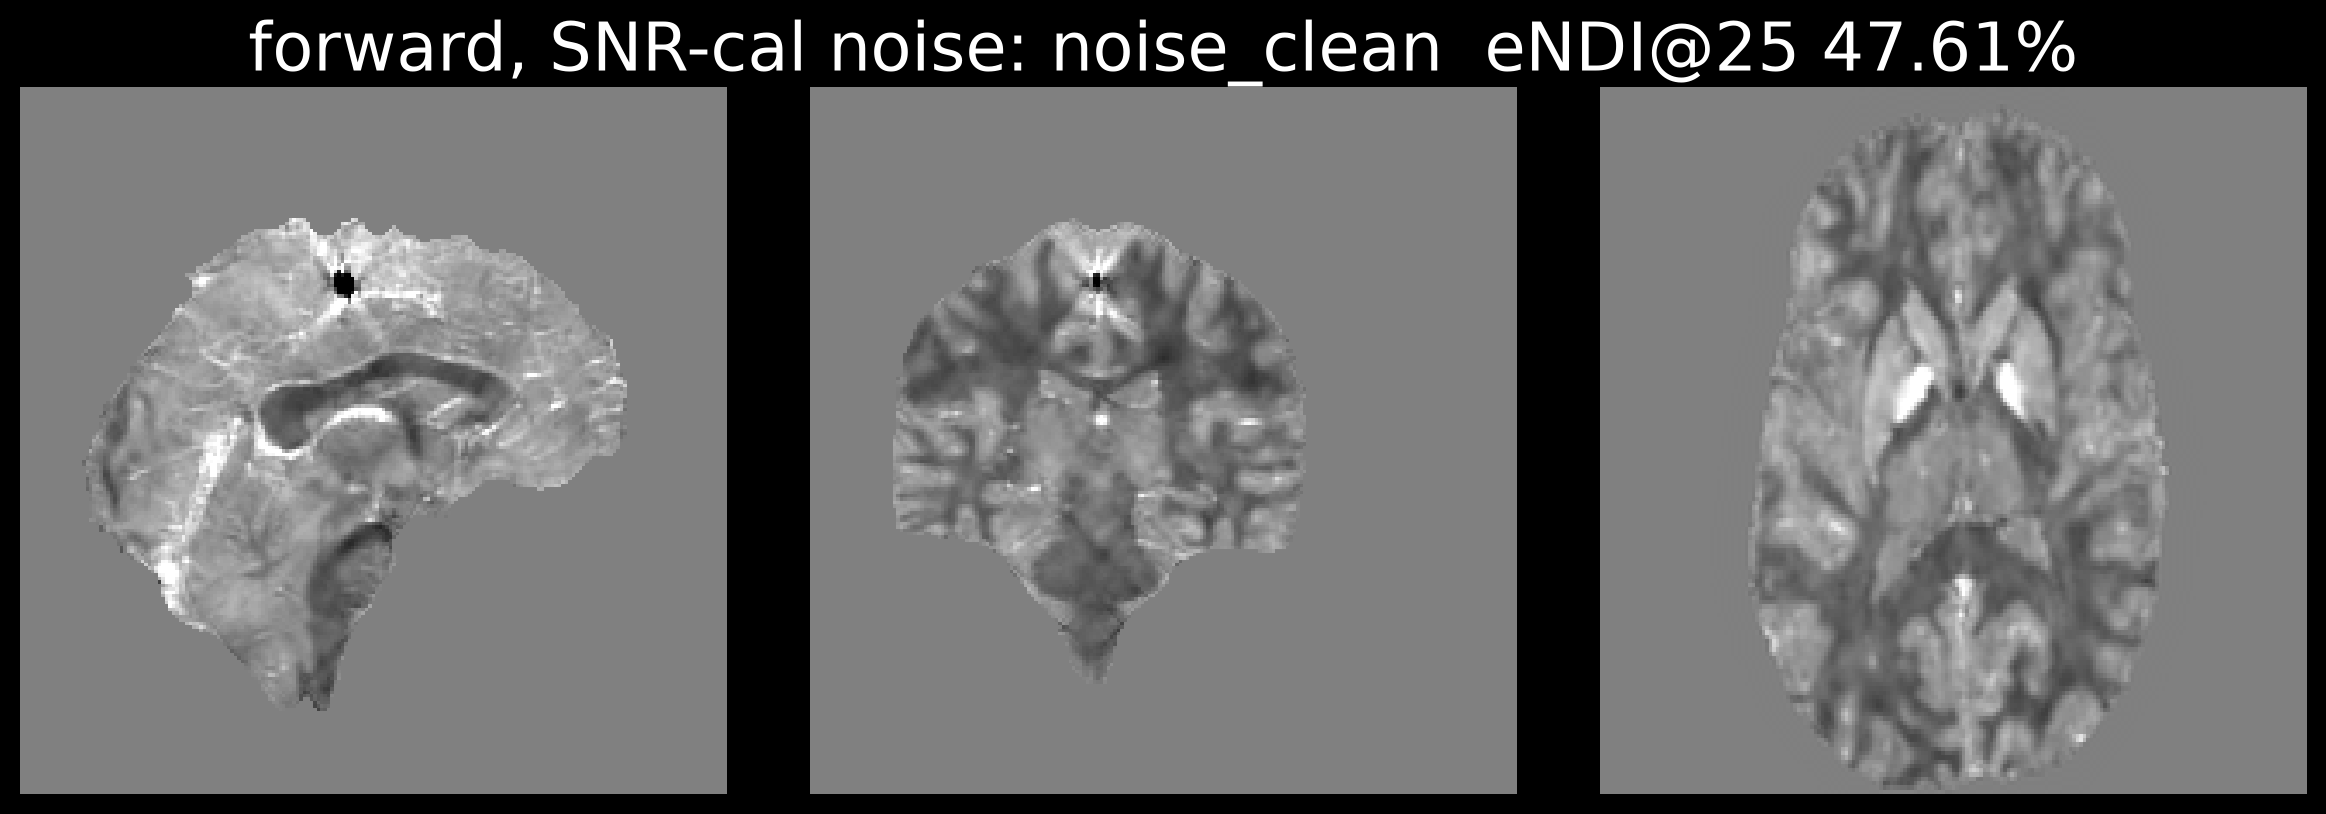

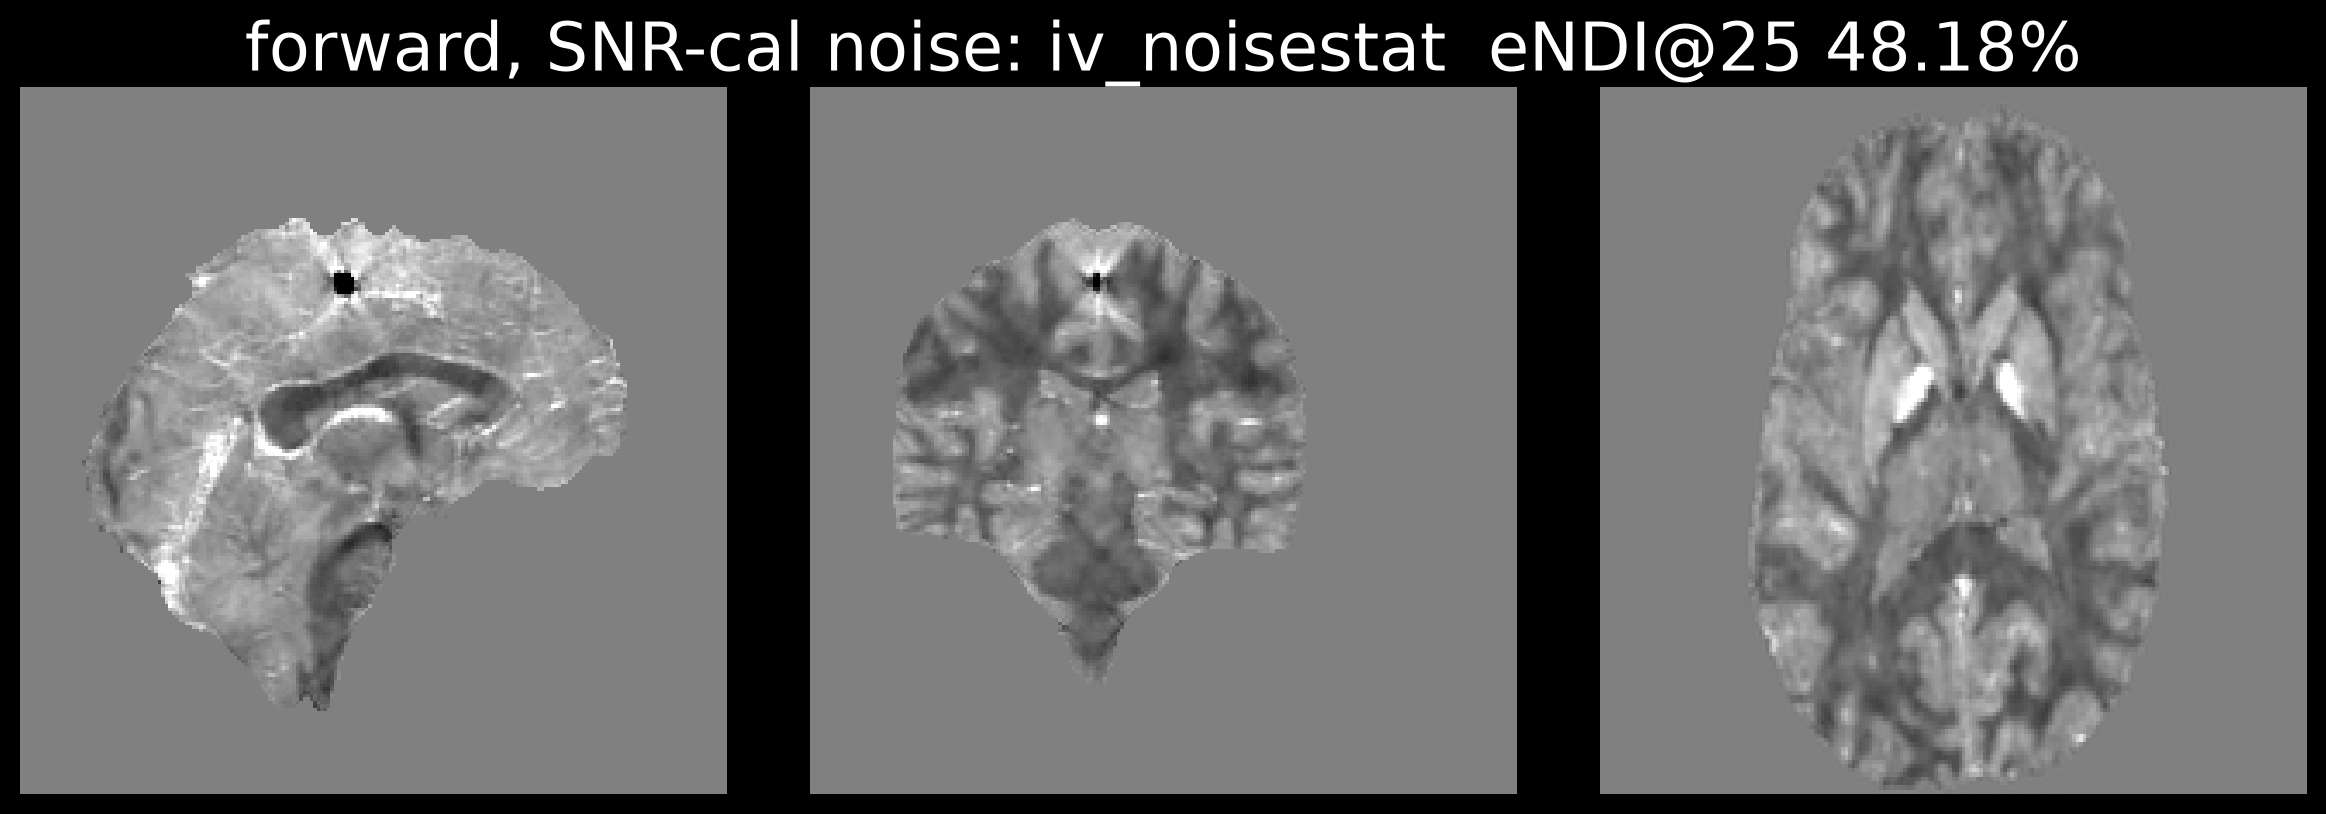

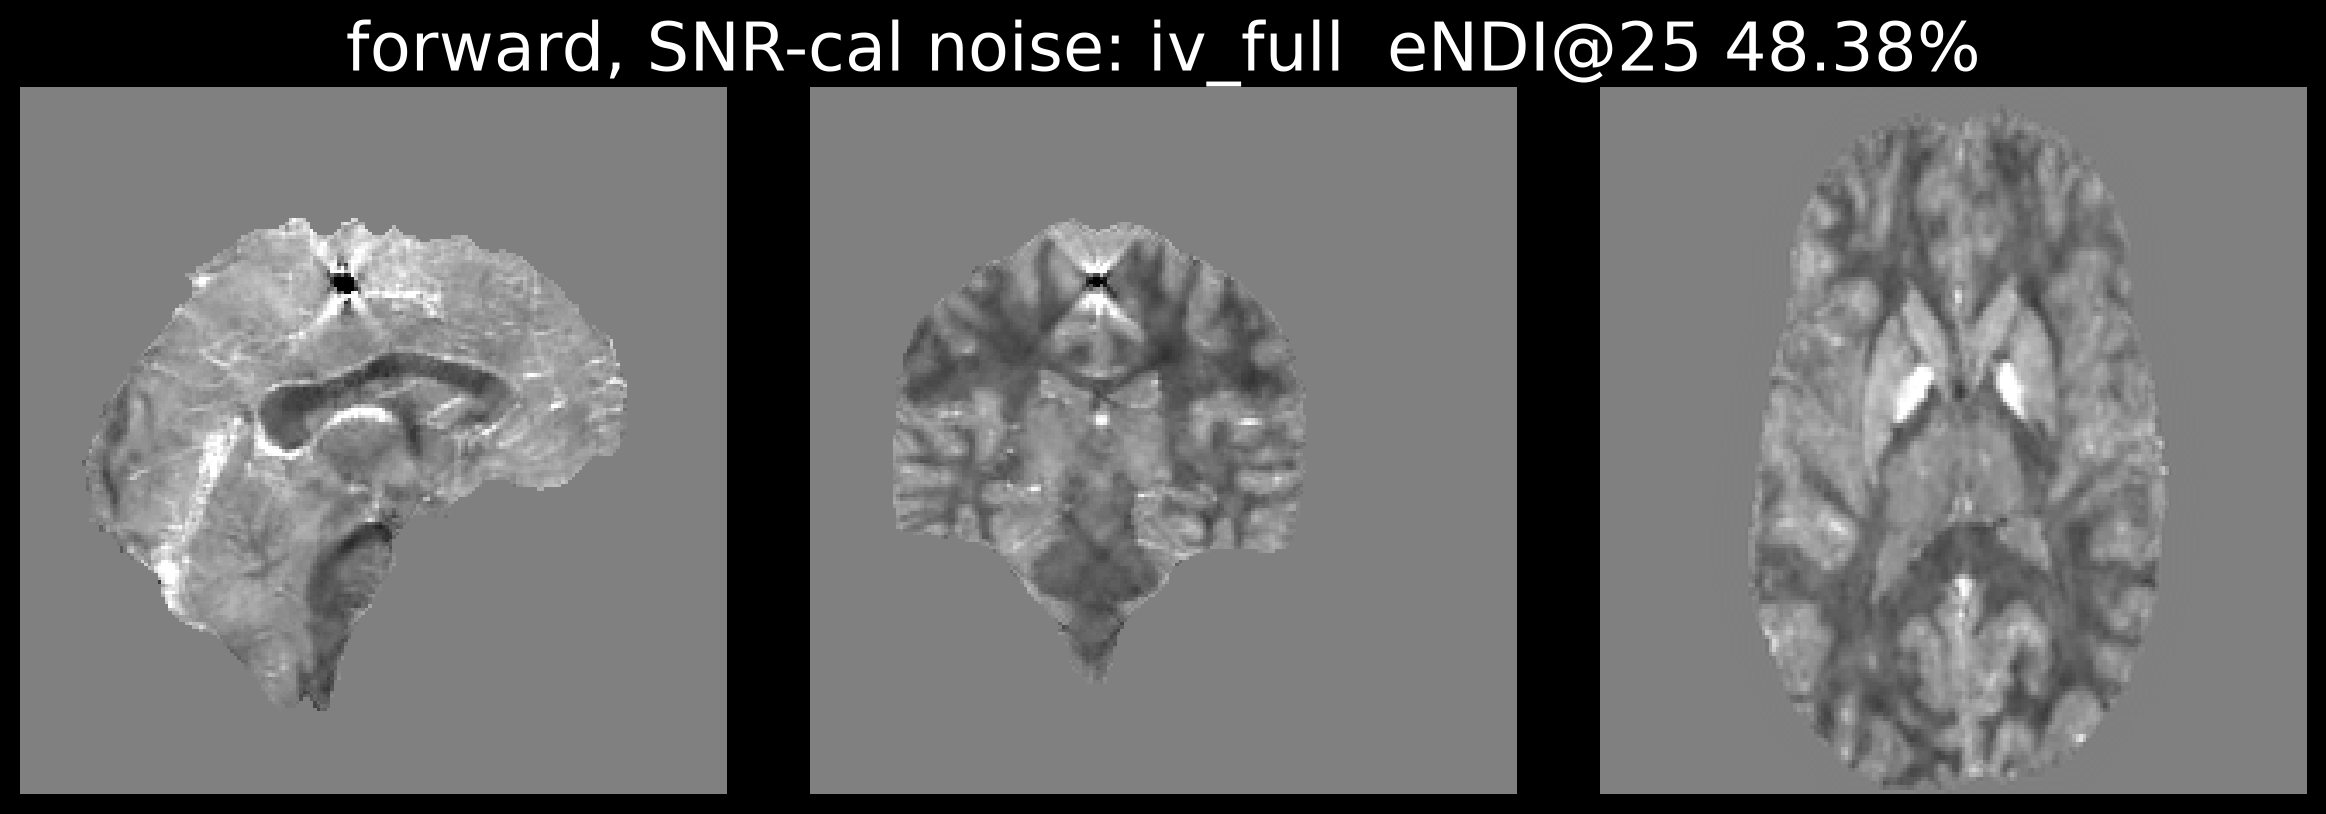

In [2]:
block('chi', 'centre', ['real', 'sim2_snrcal'], CHI, 'chi centre')

## 2. Susceptibility at the calcification (ppm)
Contrast as the paper views (-0.1 .. 0.1), so the strong source saturates: look at the streaks and the halo around it.

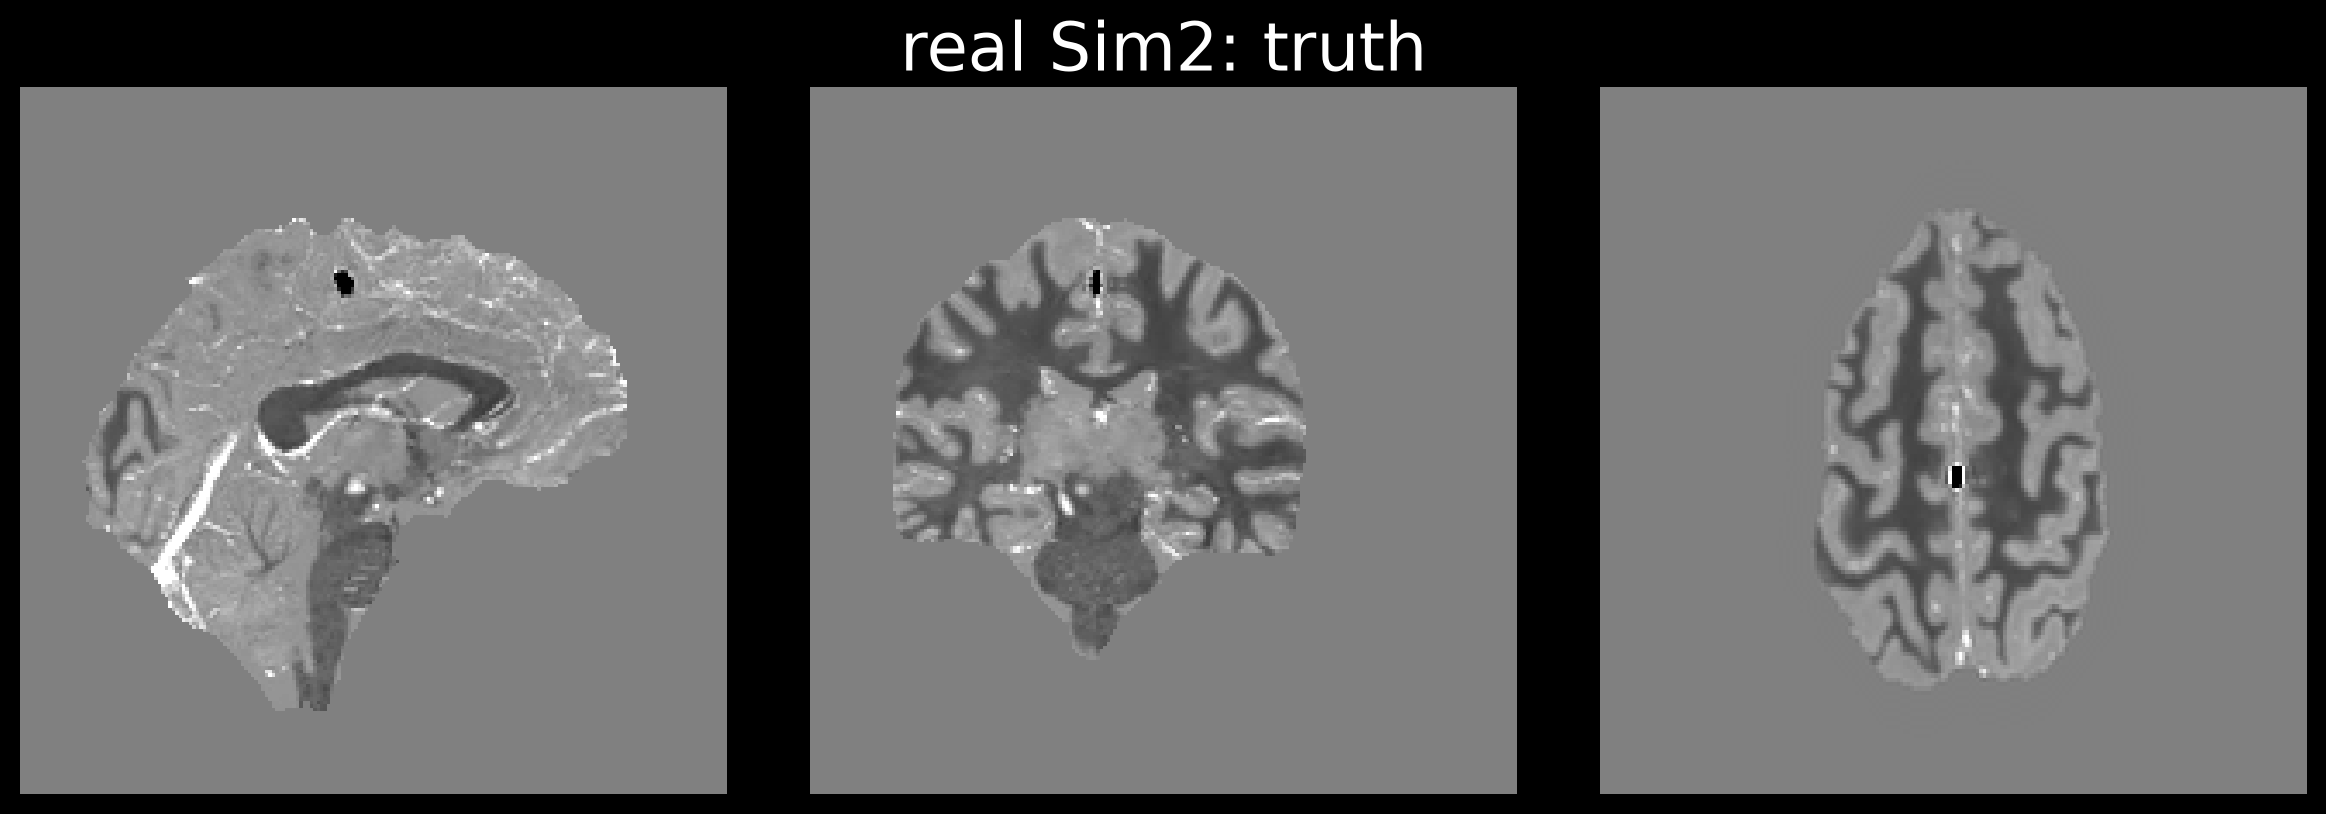

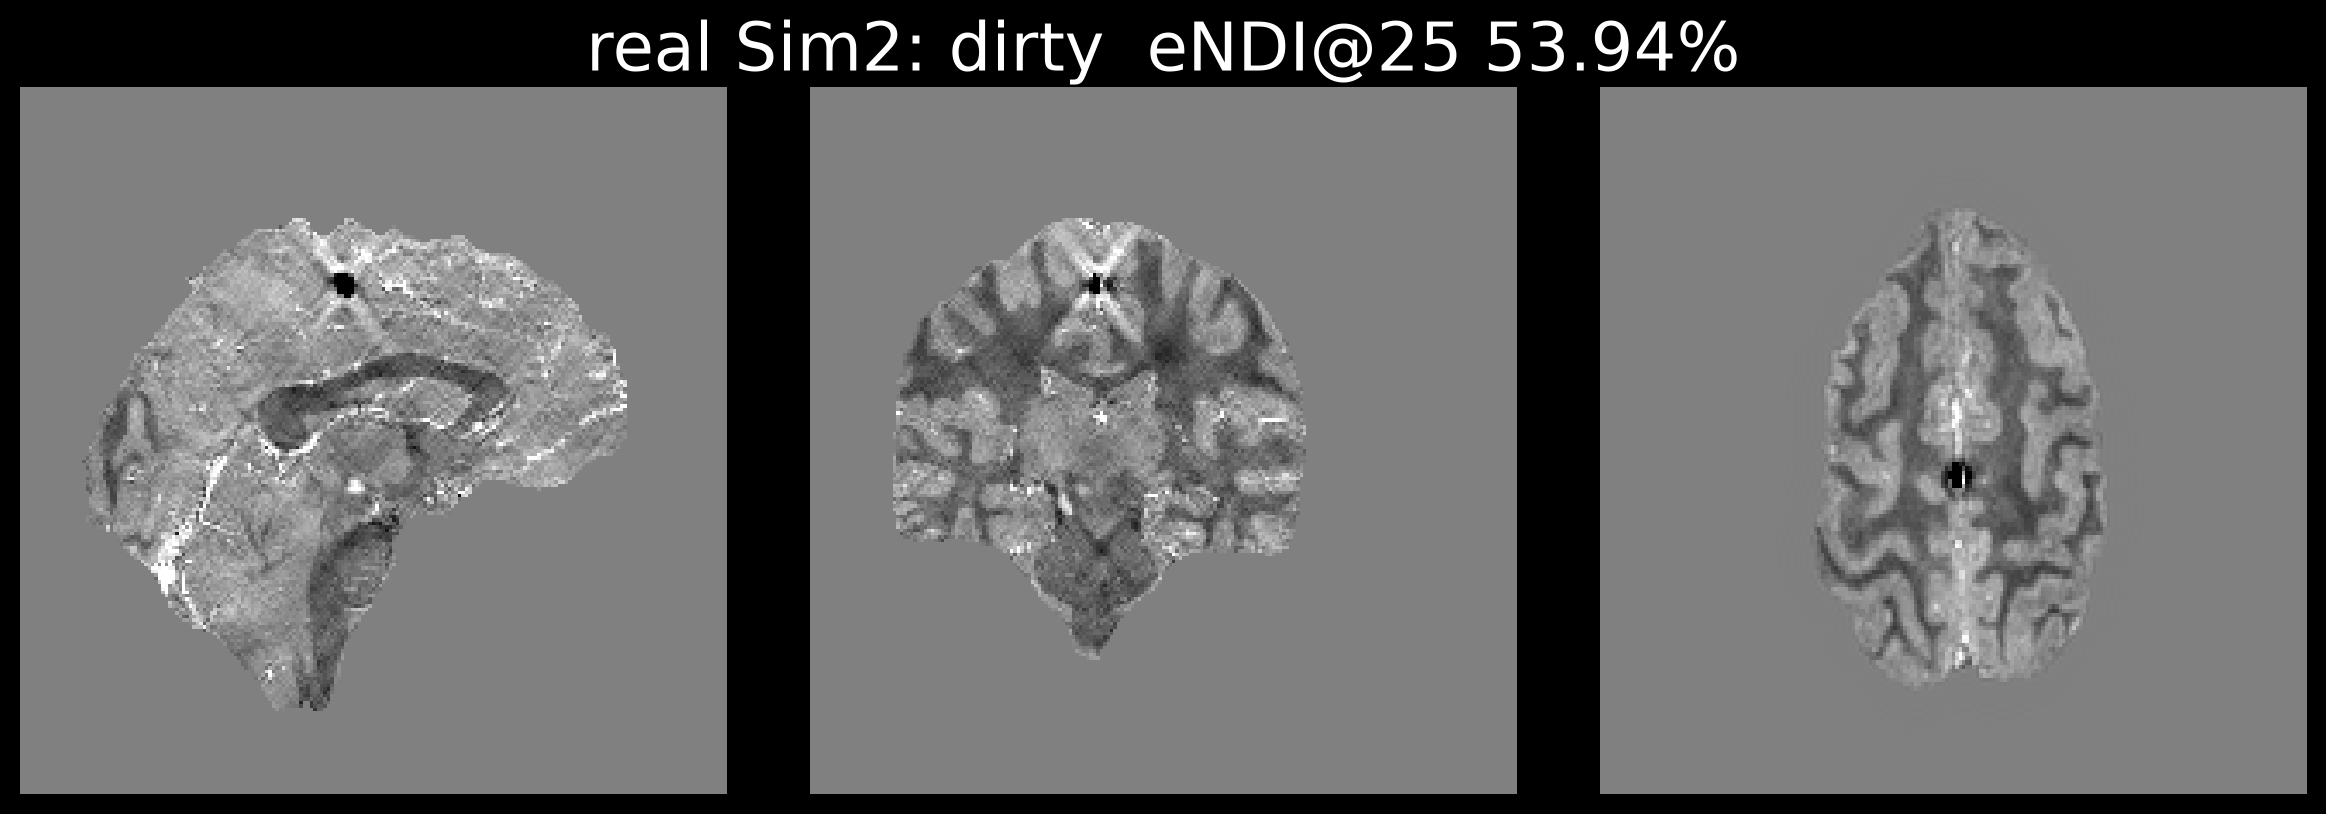

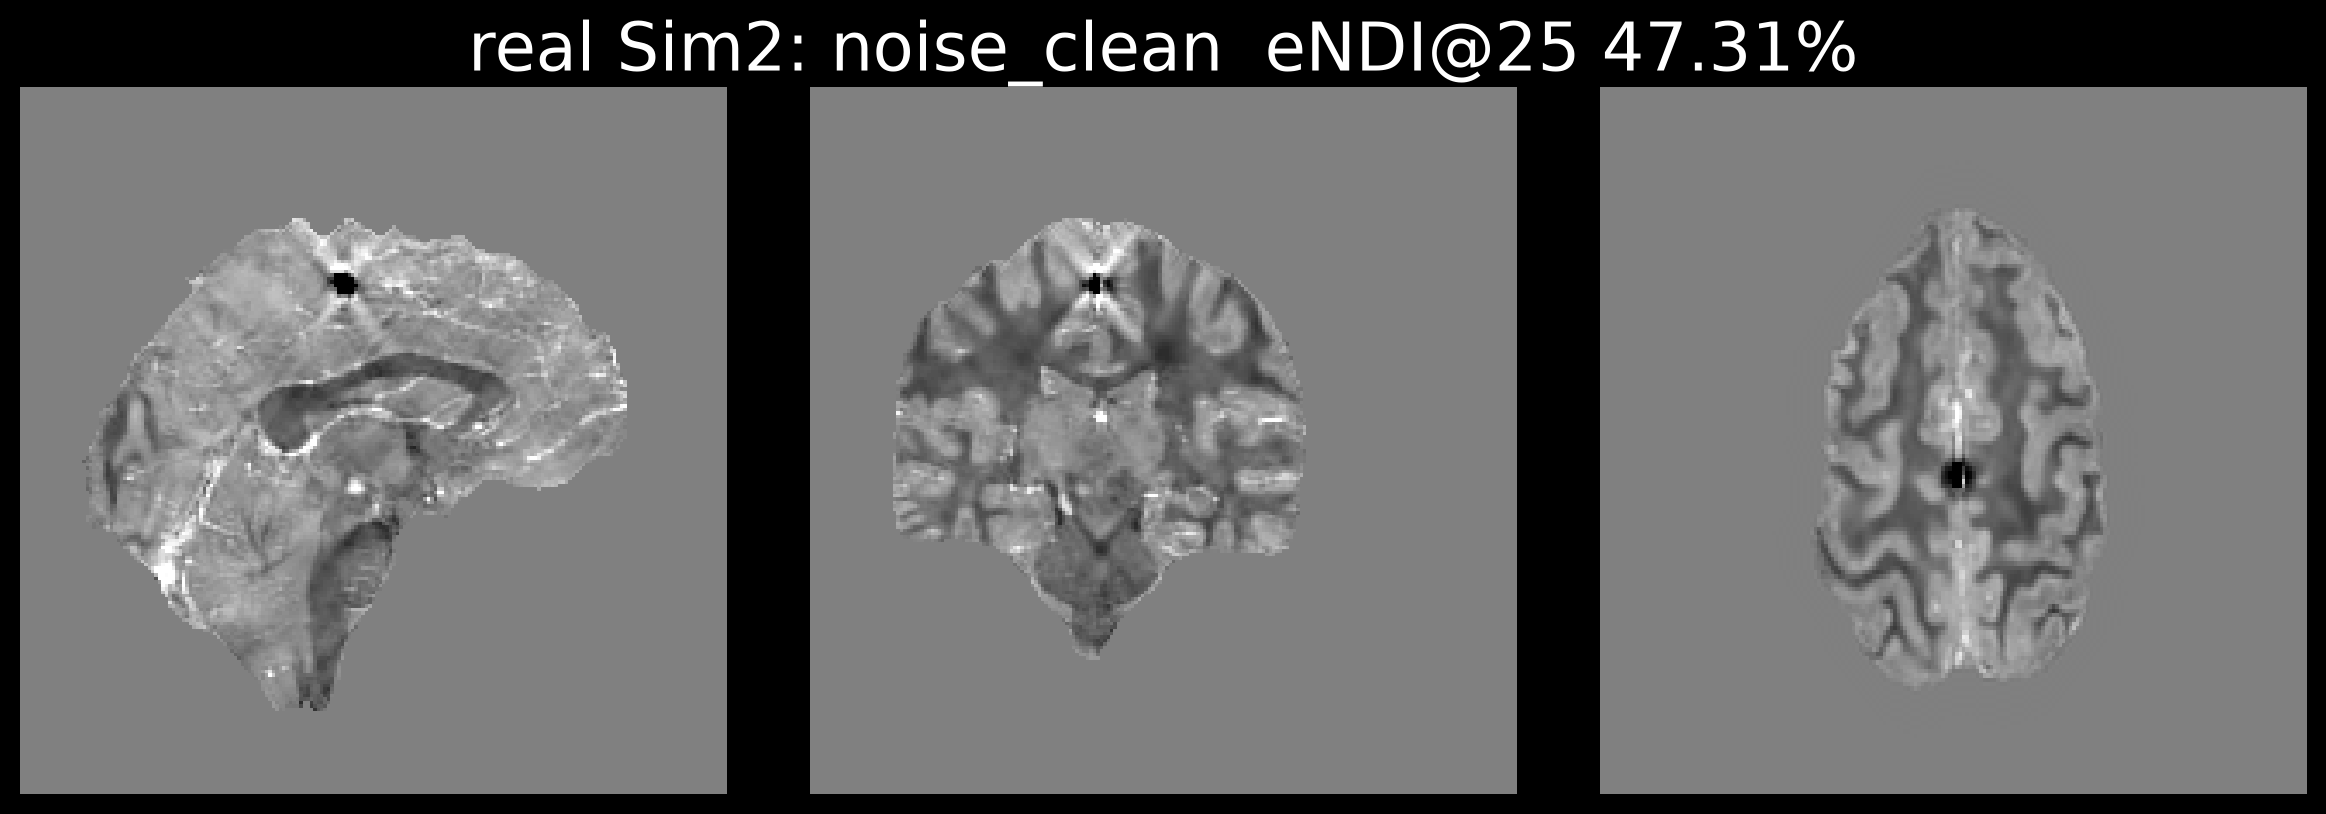

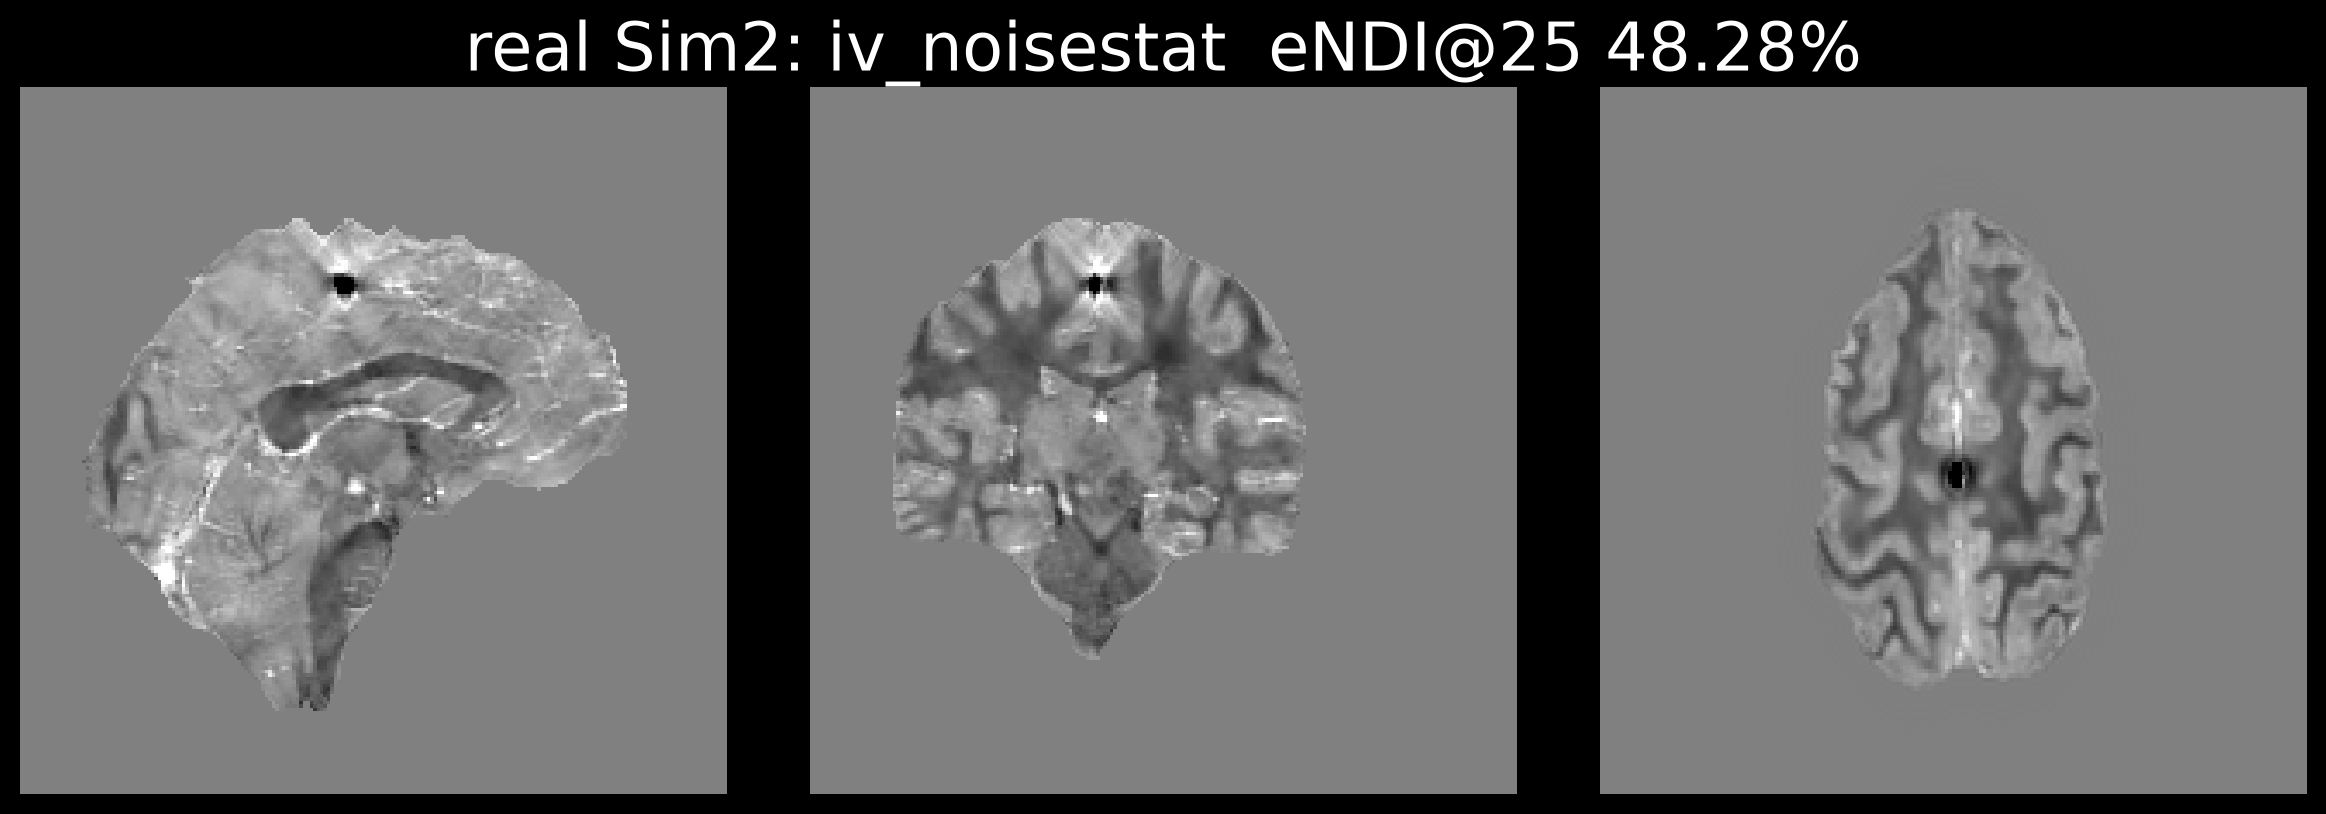

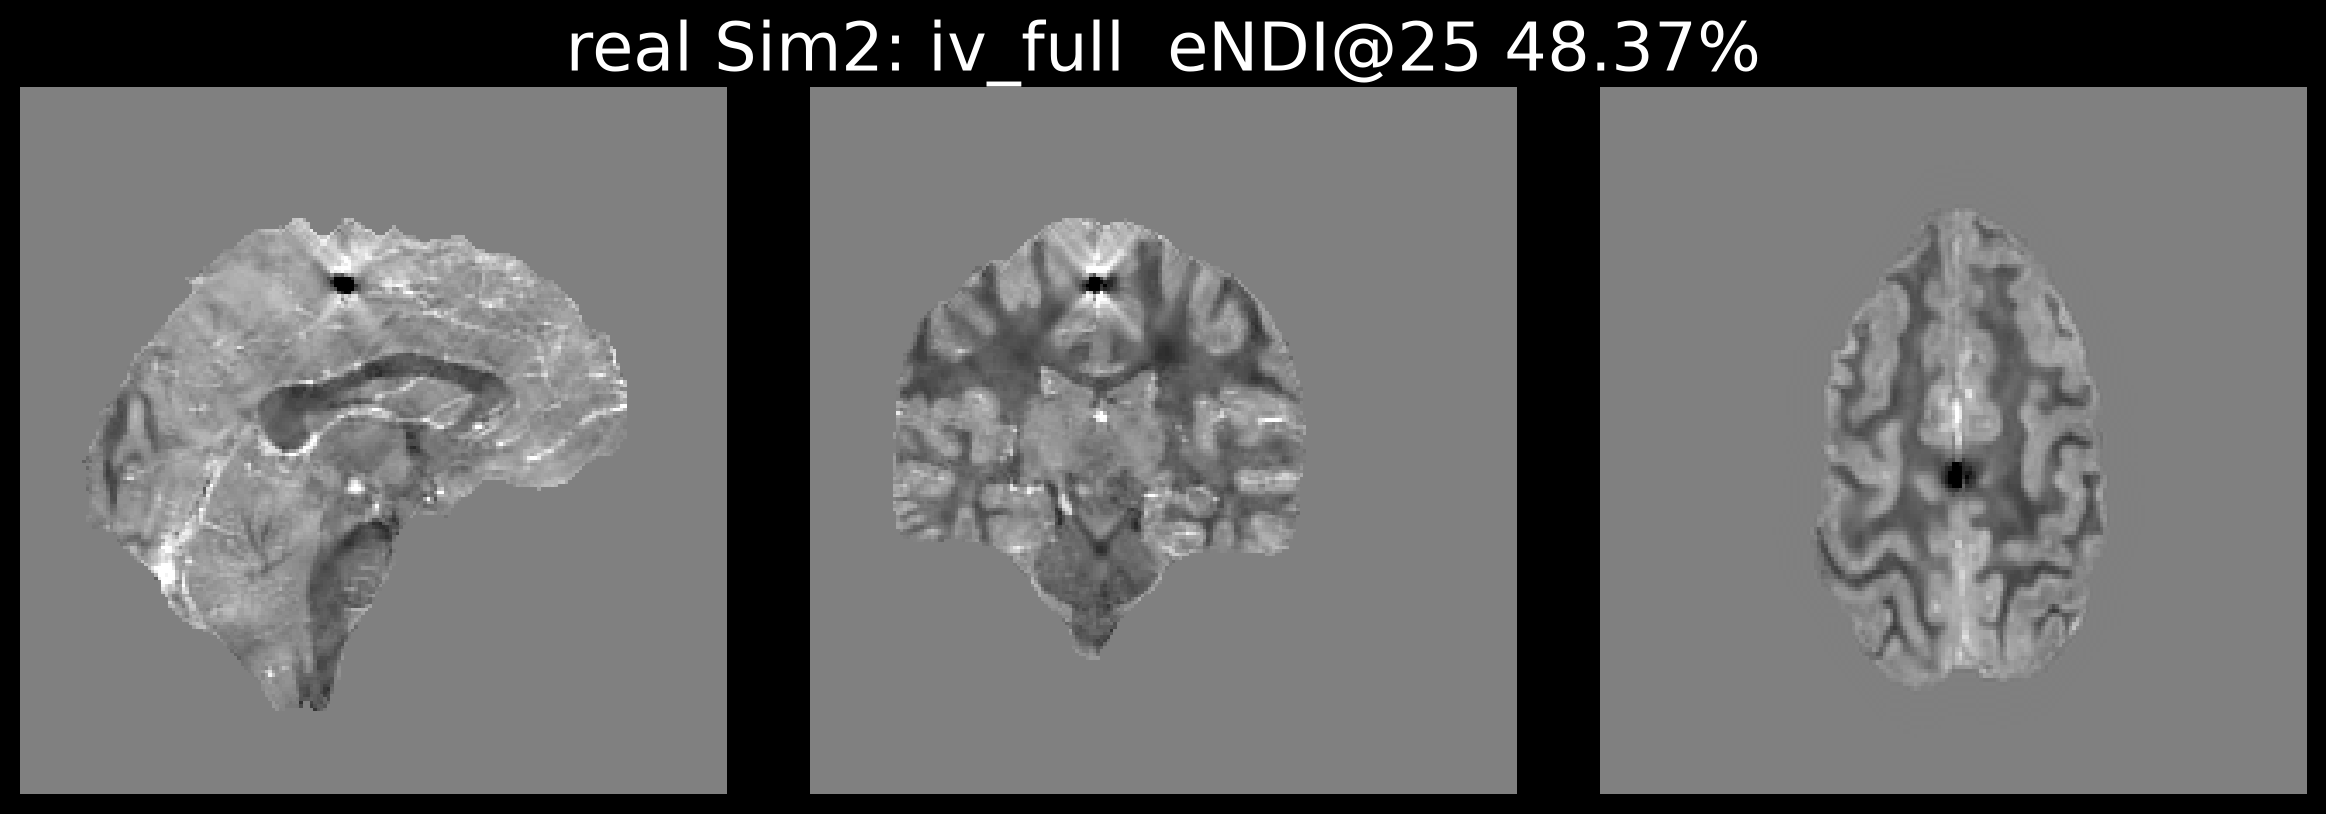

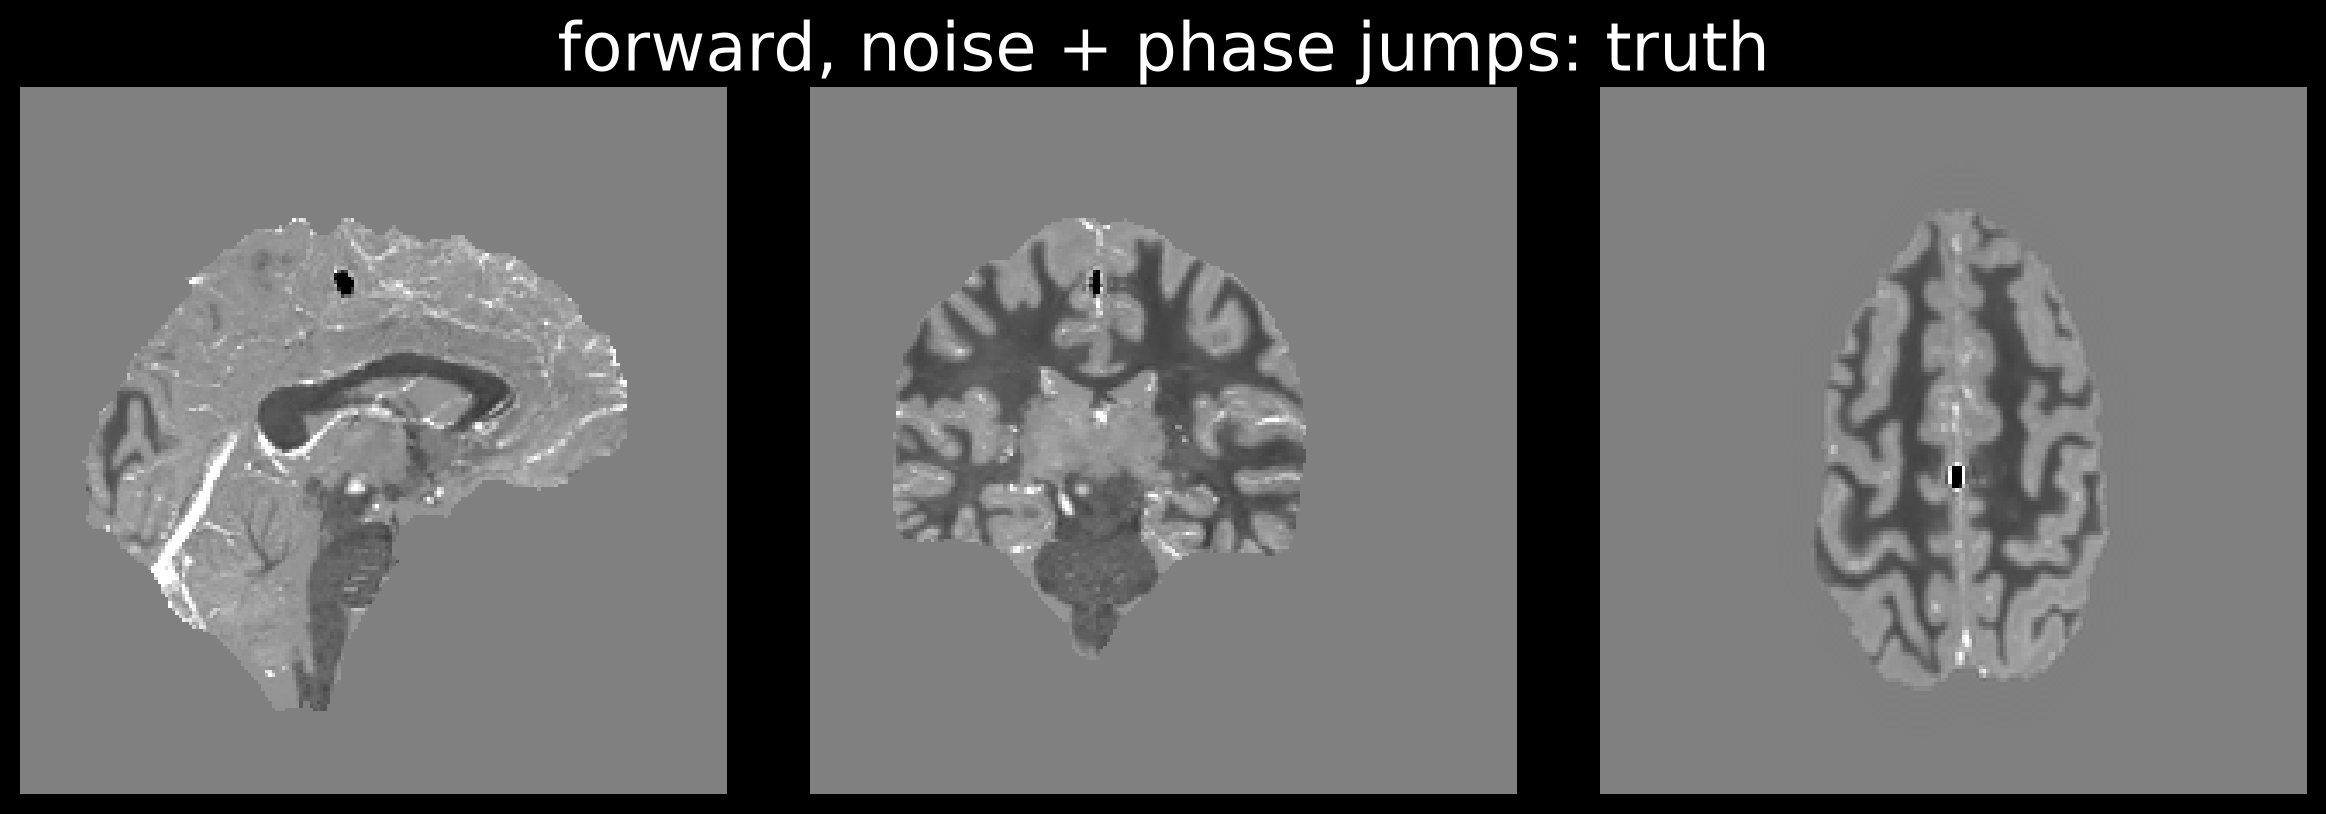

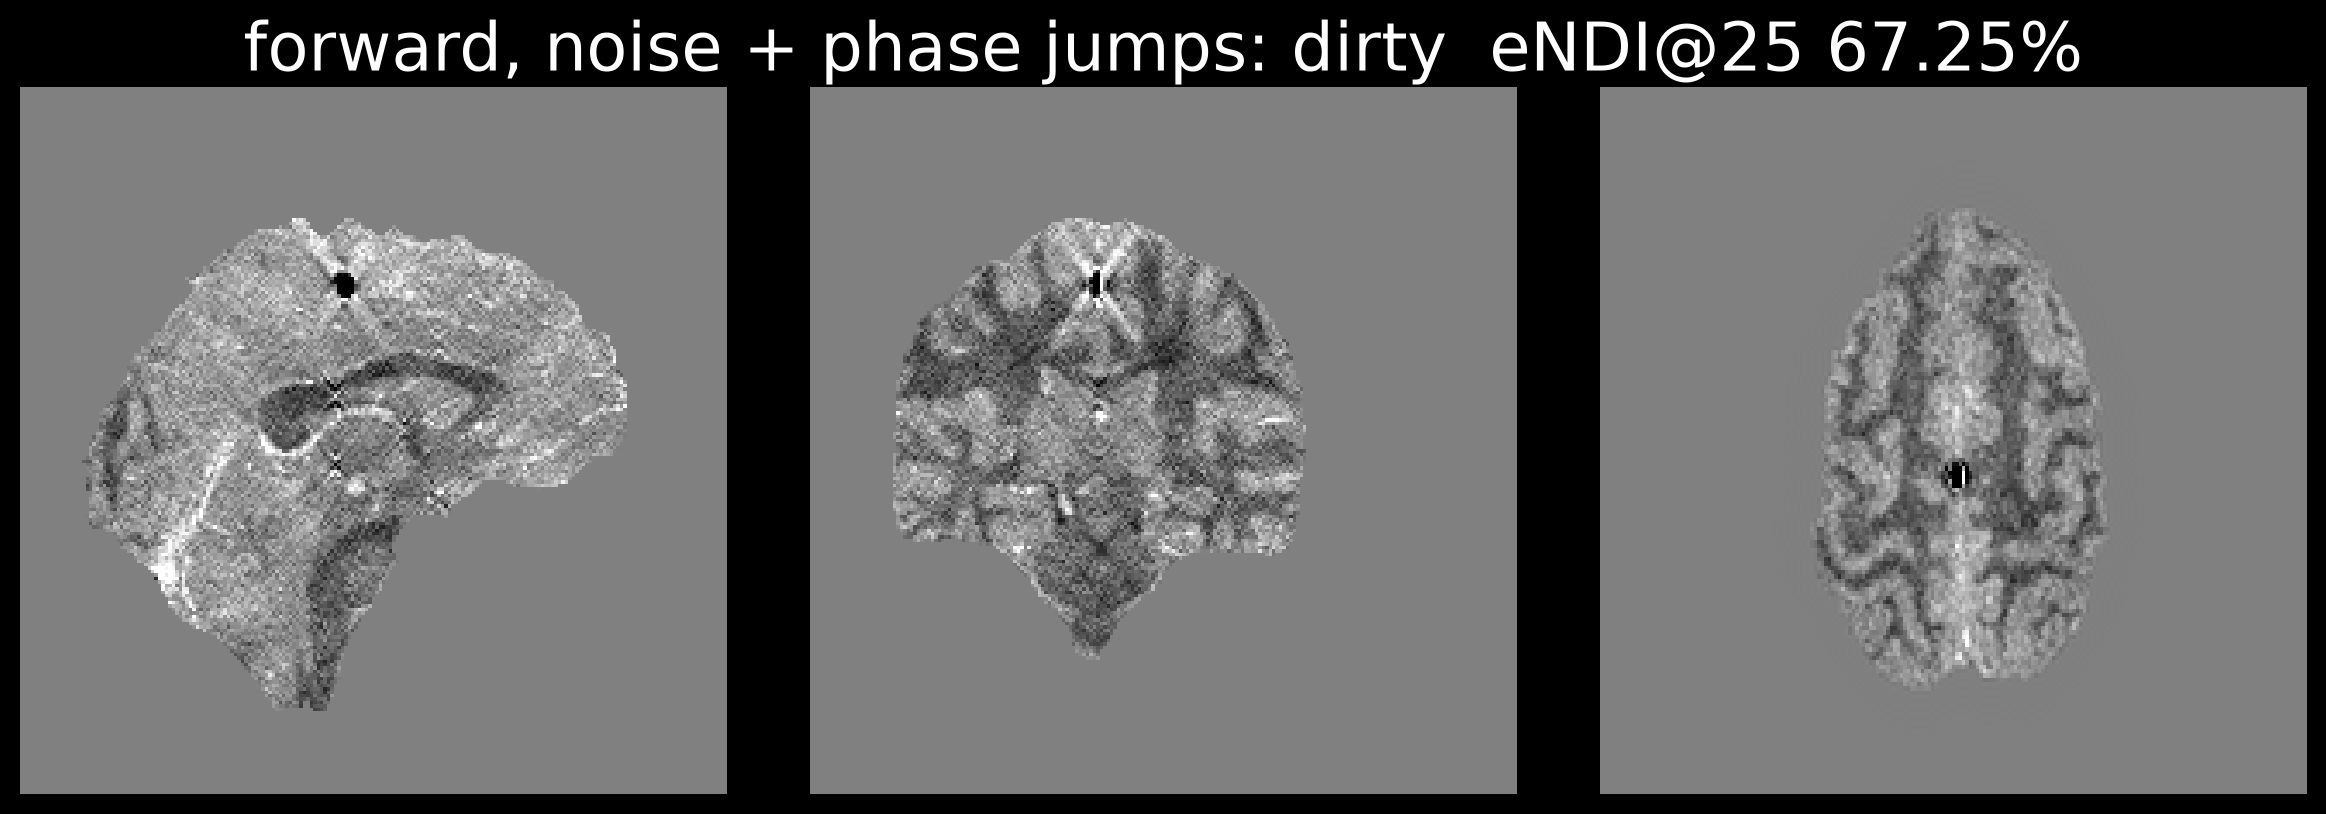

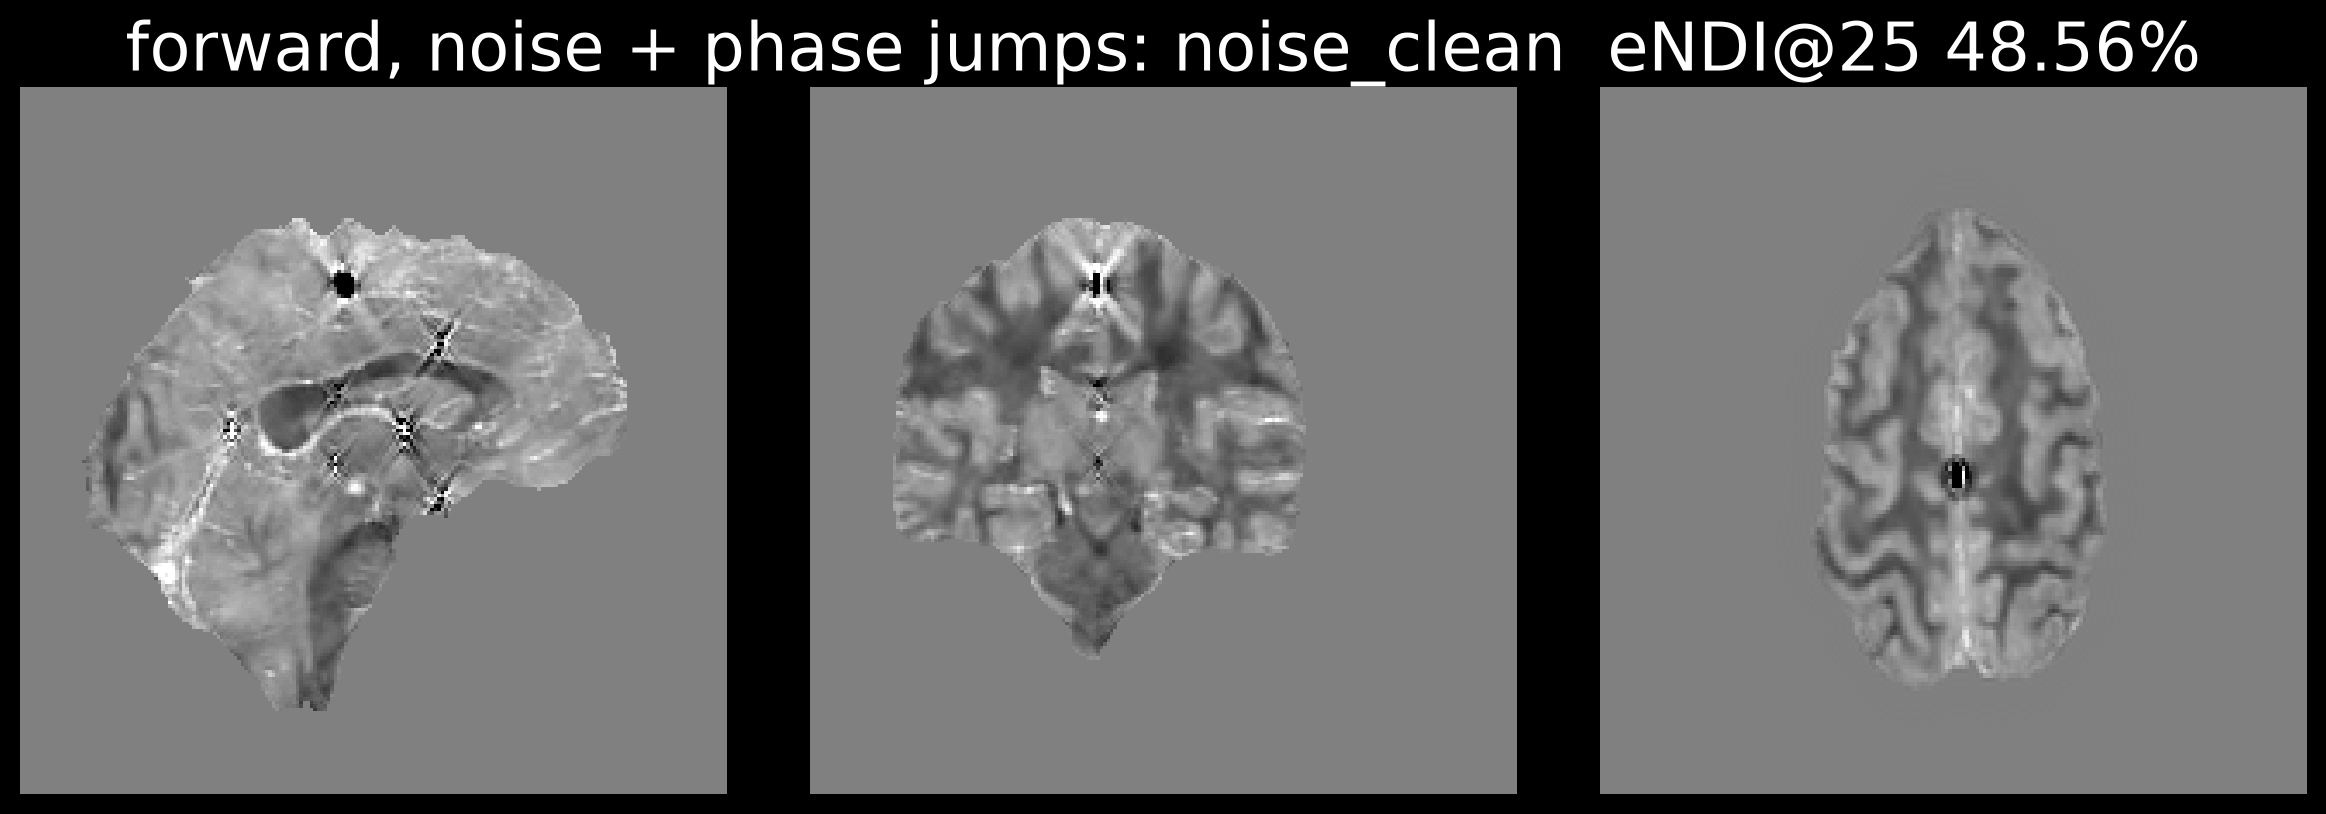

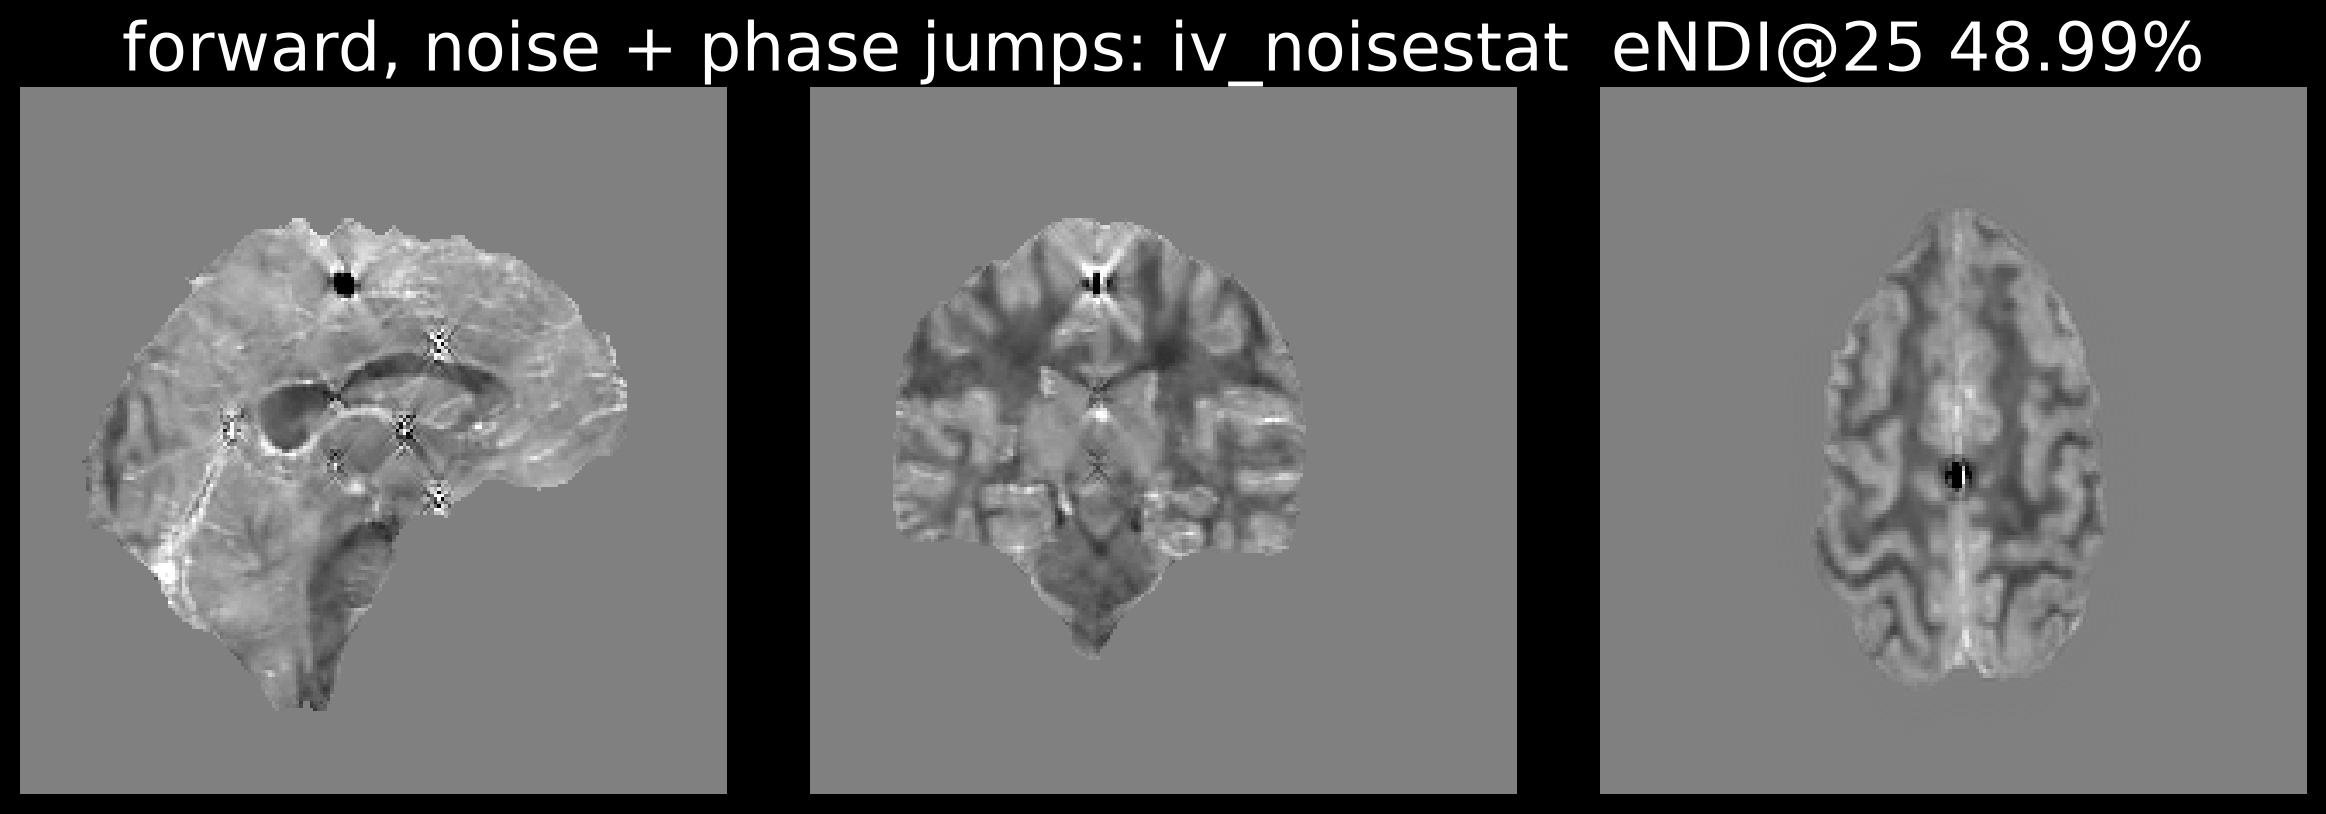

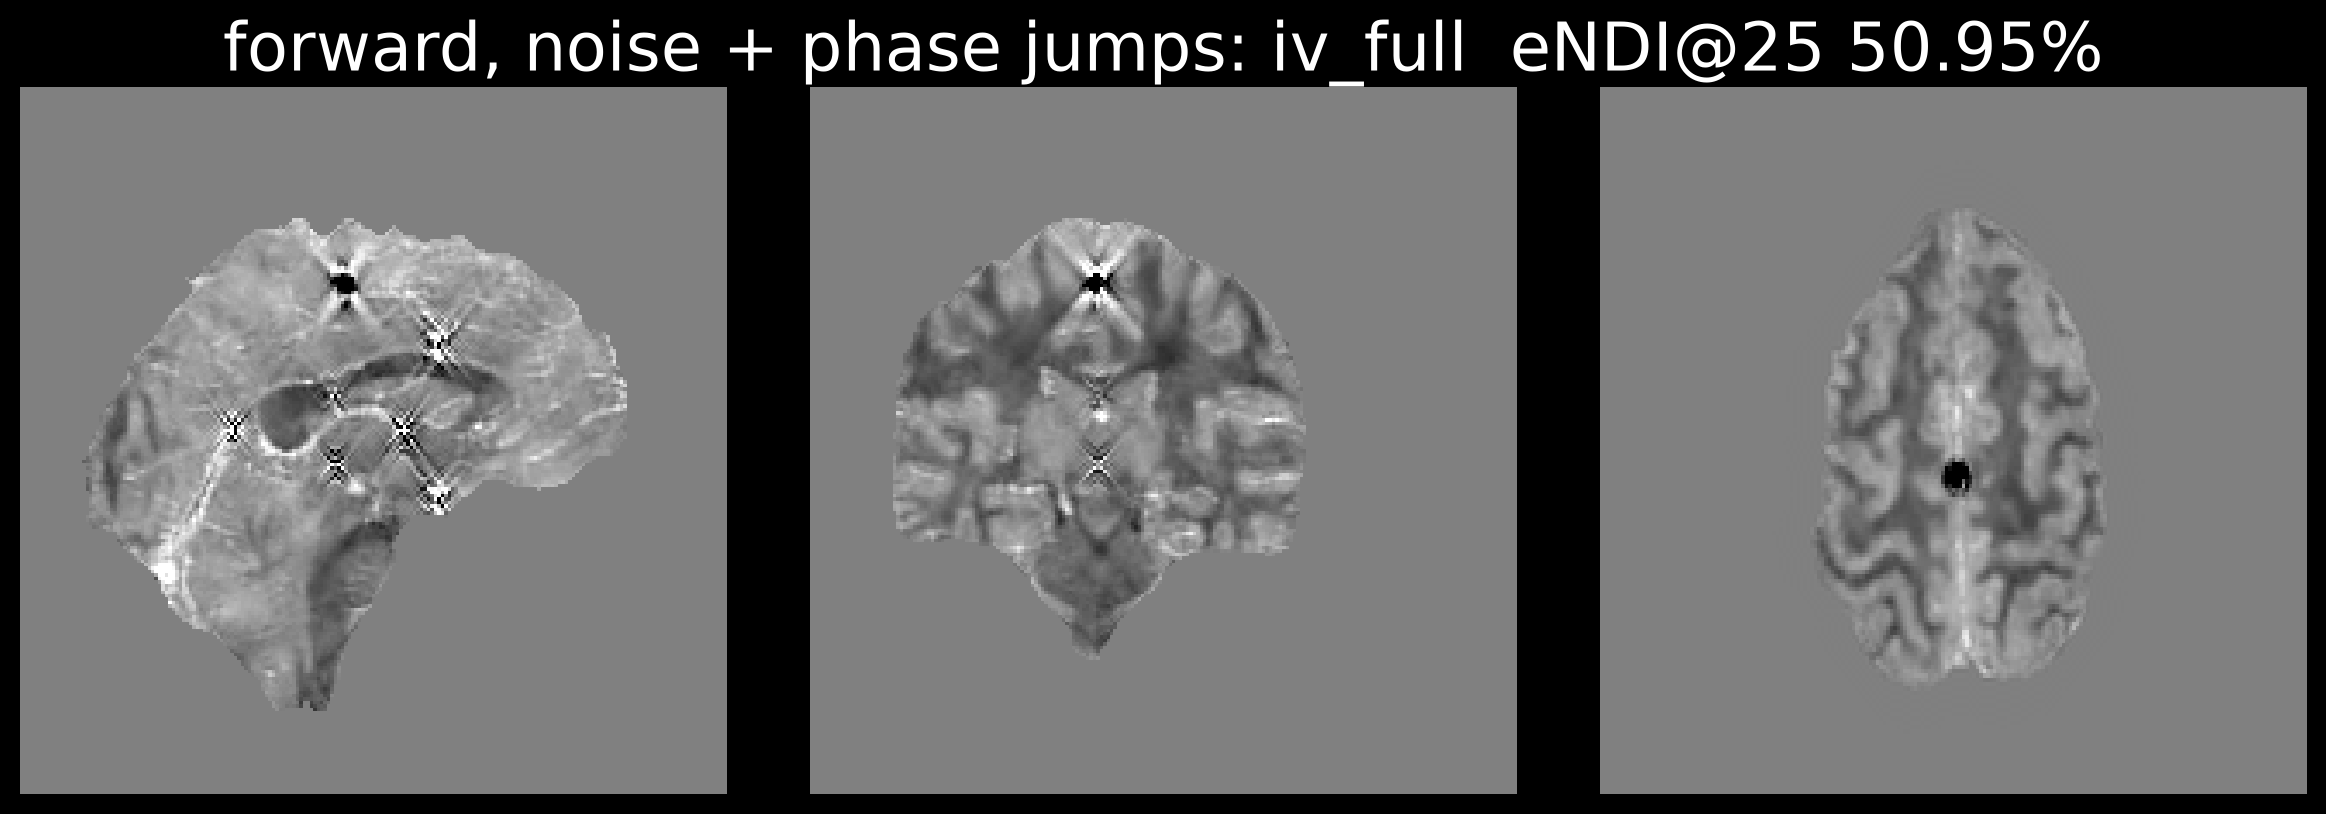

In [3]:
block('chi', 'calc', ['real', 'sim2_jumps'], CHI, 'chi calc')

## 3. The cleaned FIELD (ppm) at the calcification, real Sim2
Truth is `mask * D*chi`. Inside about 3 mm the input has lost most of the true field (9ak); look at whether the cleaned fields keep, erase or invent it.

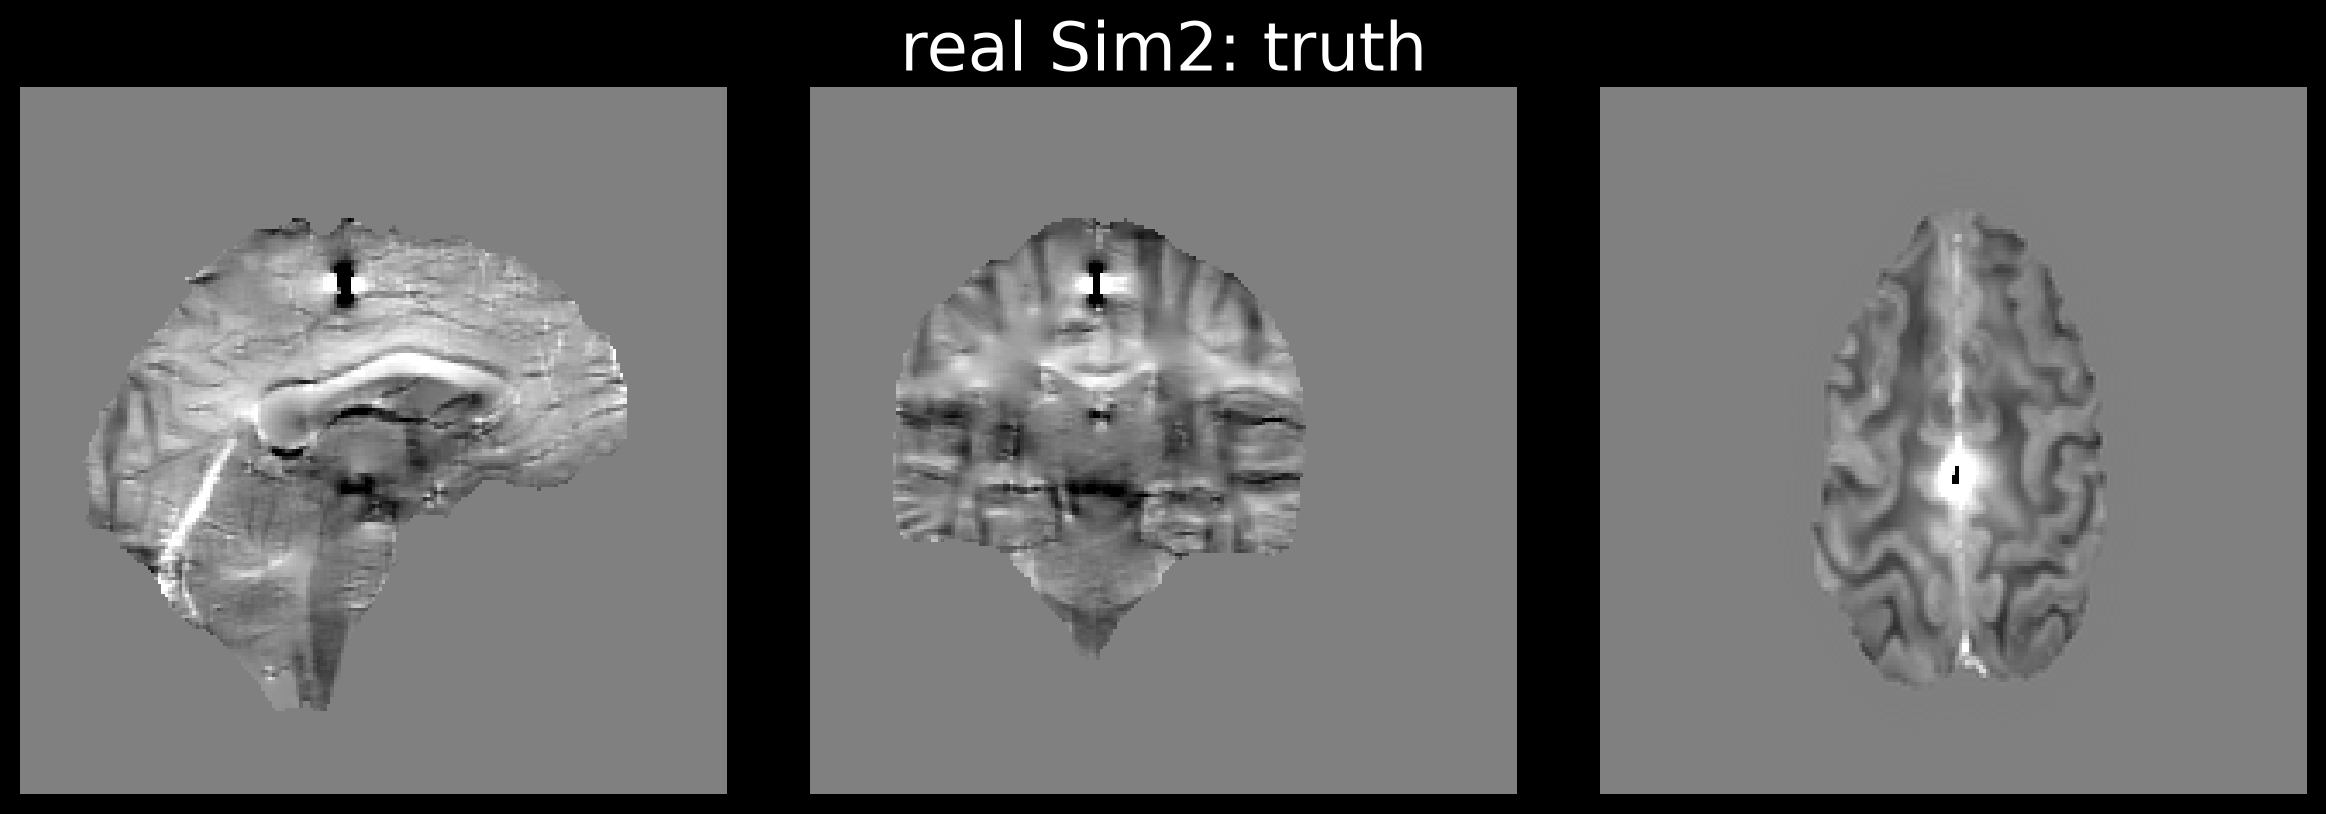

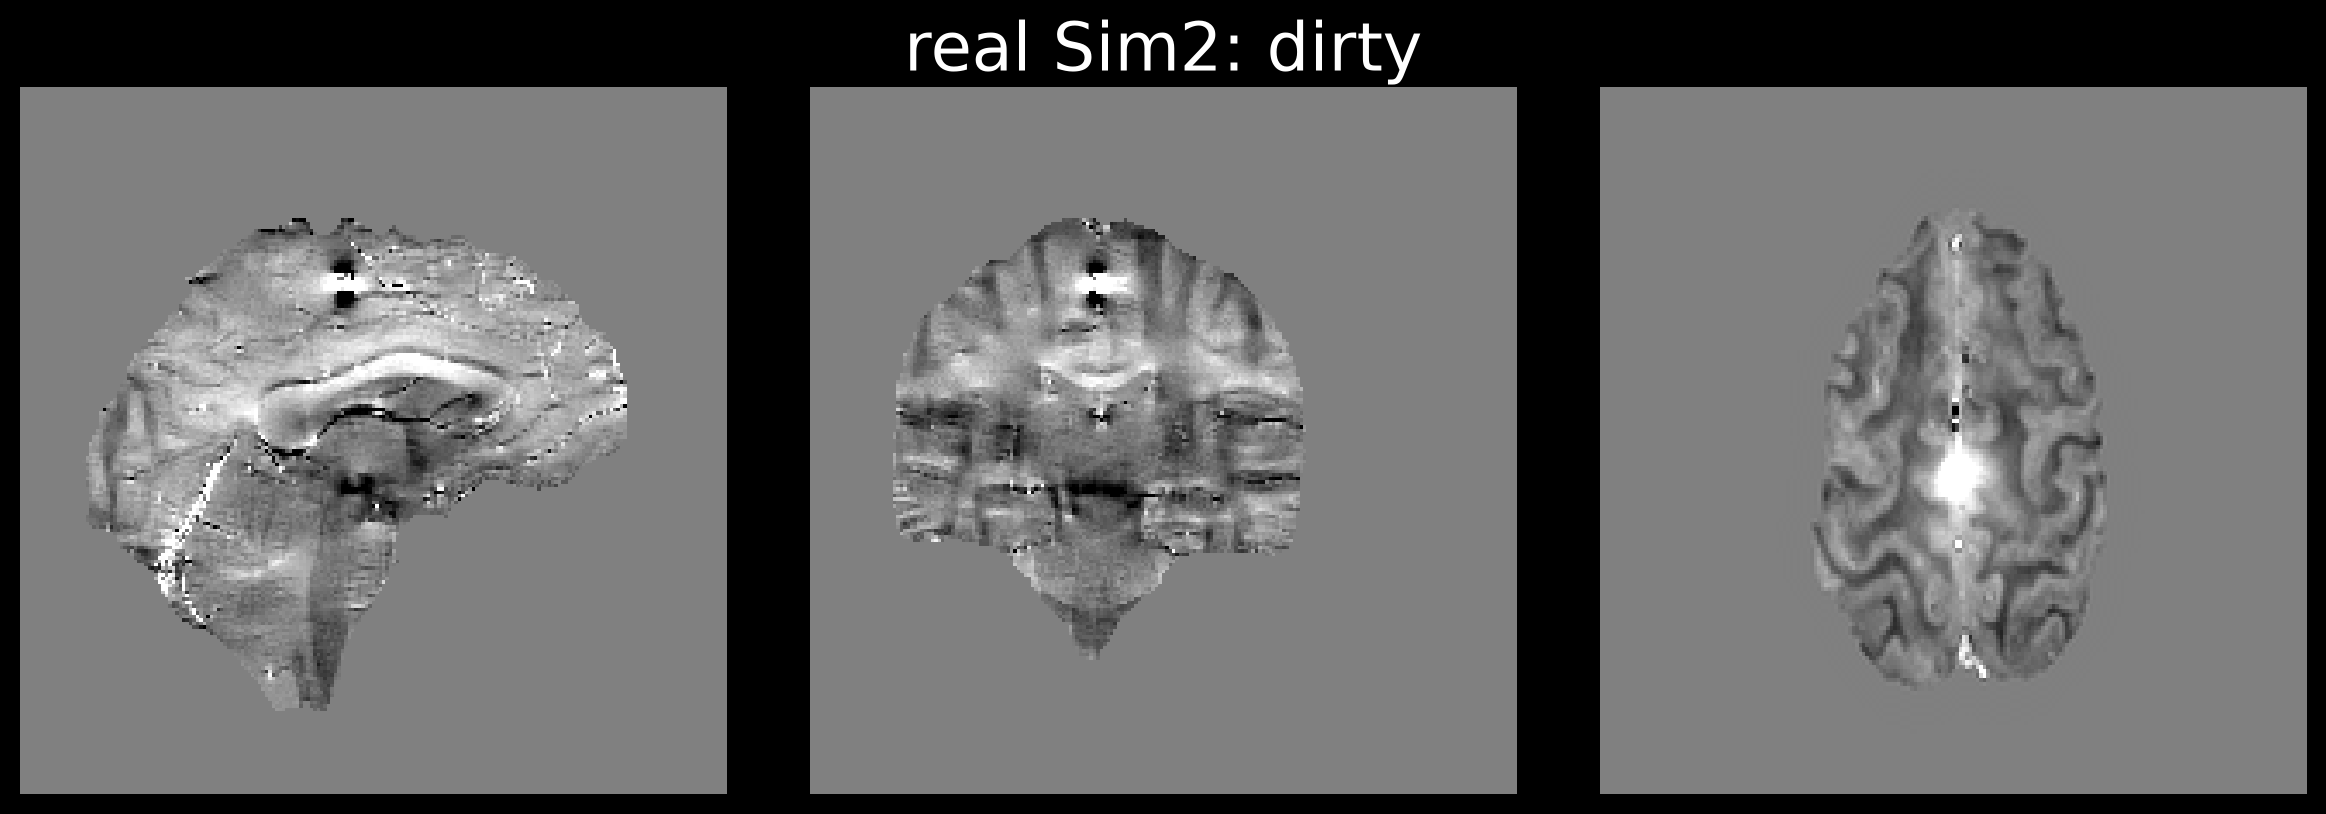

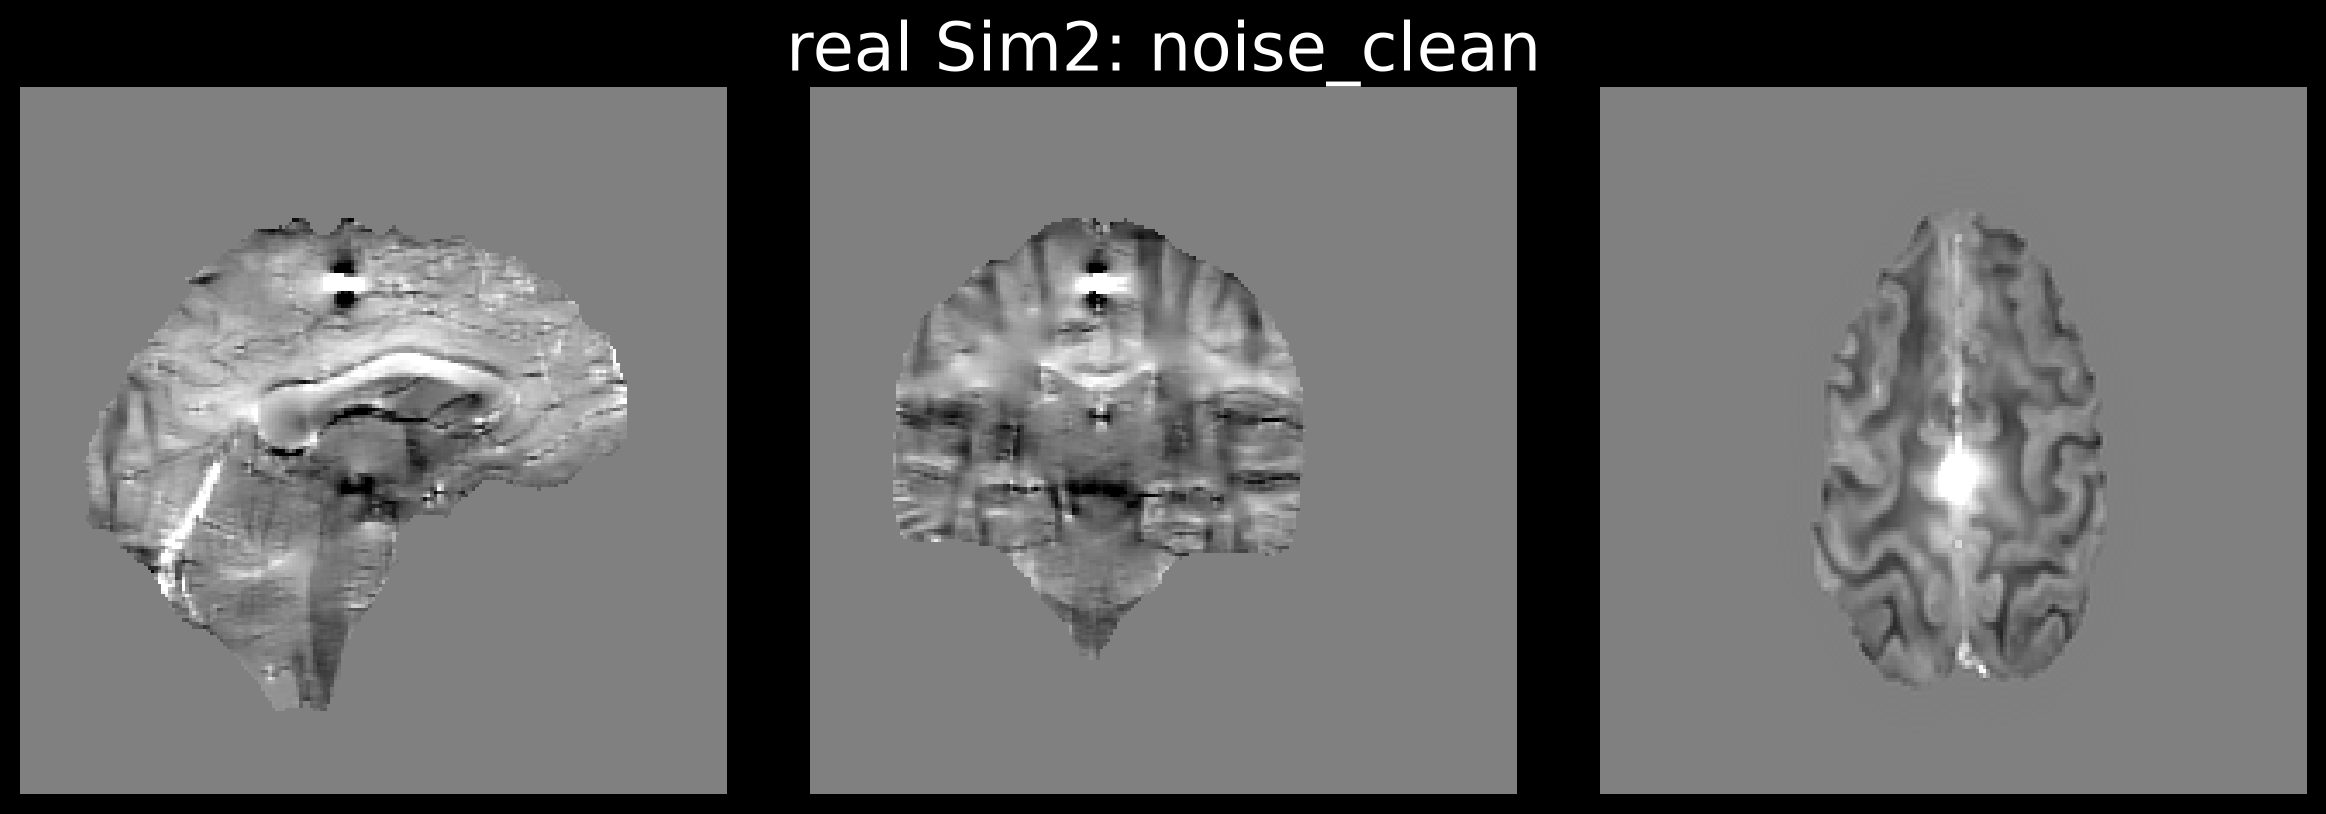

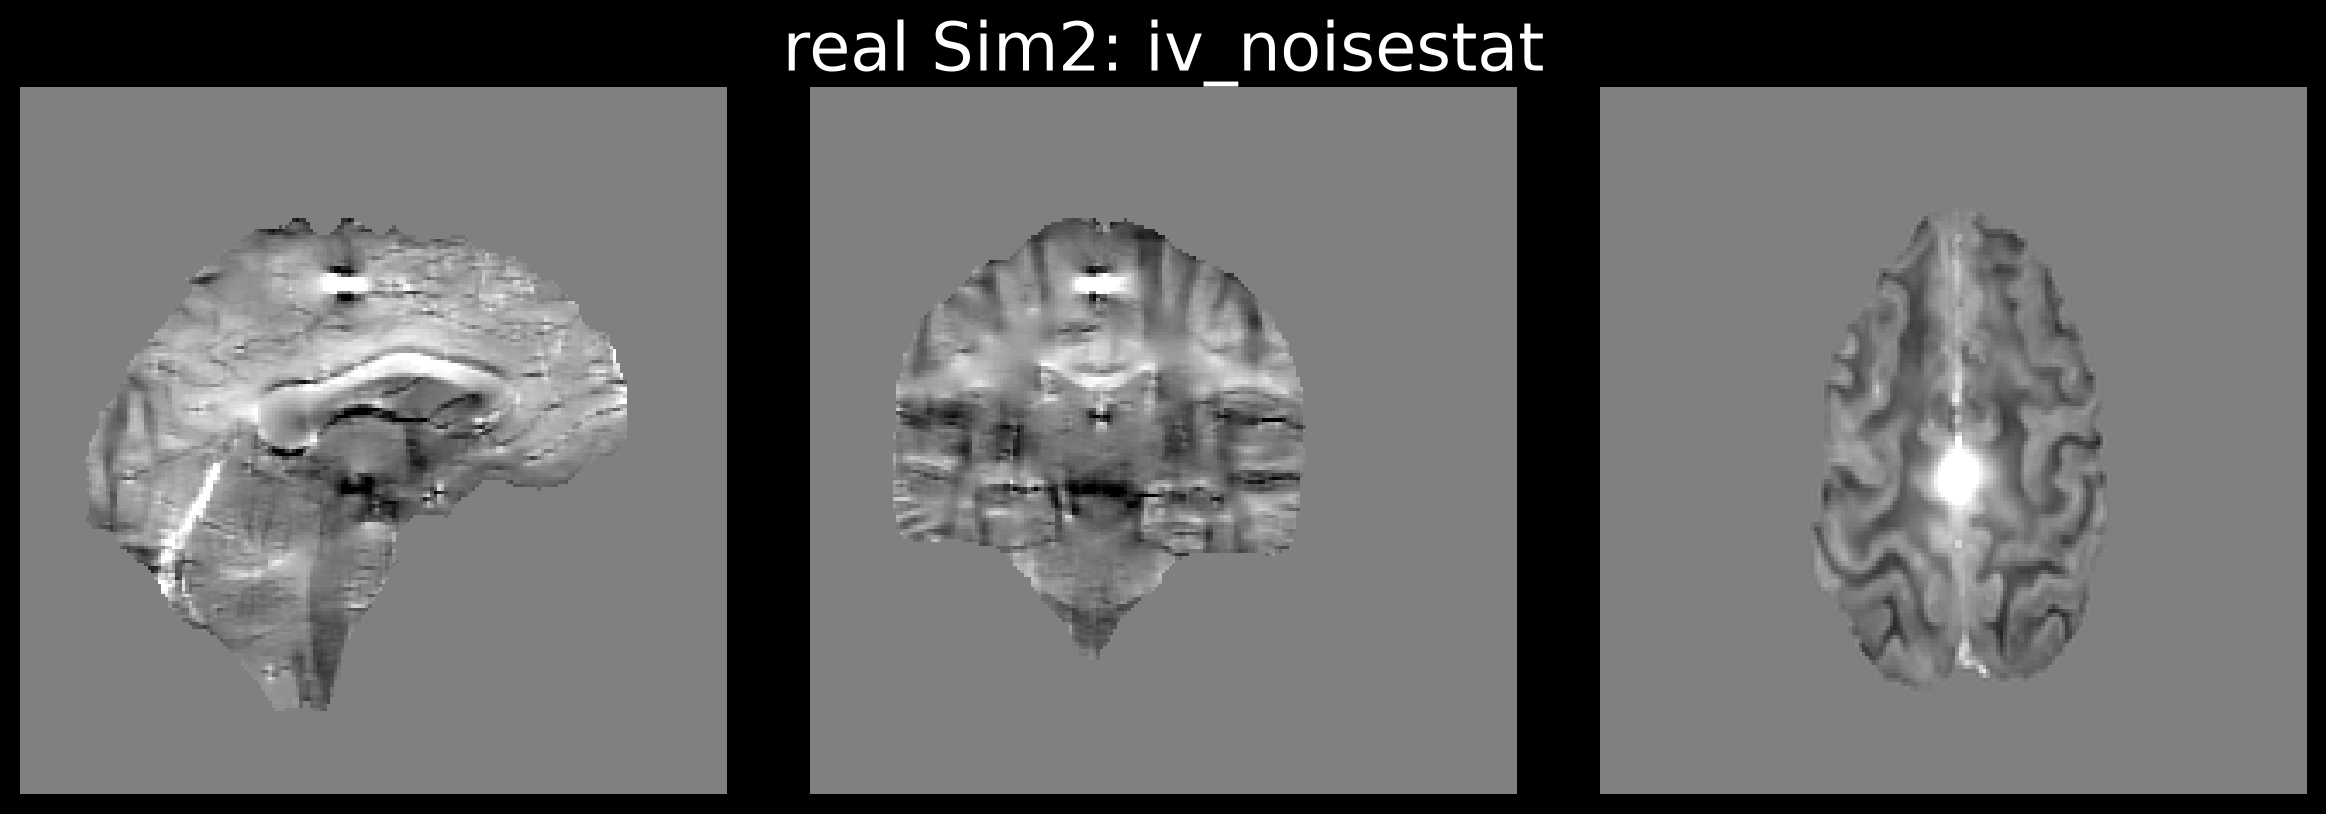

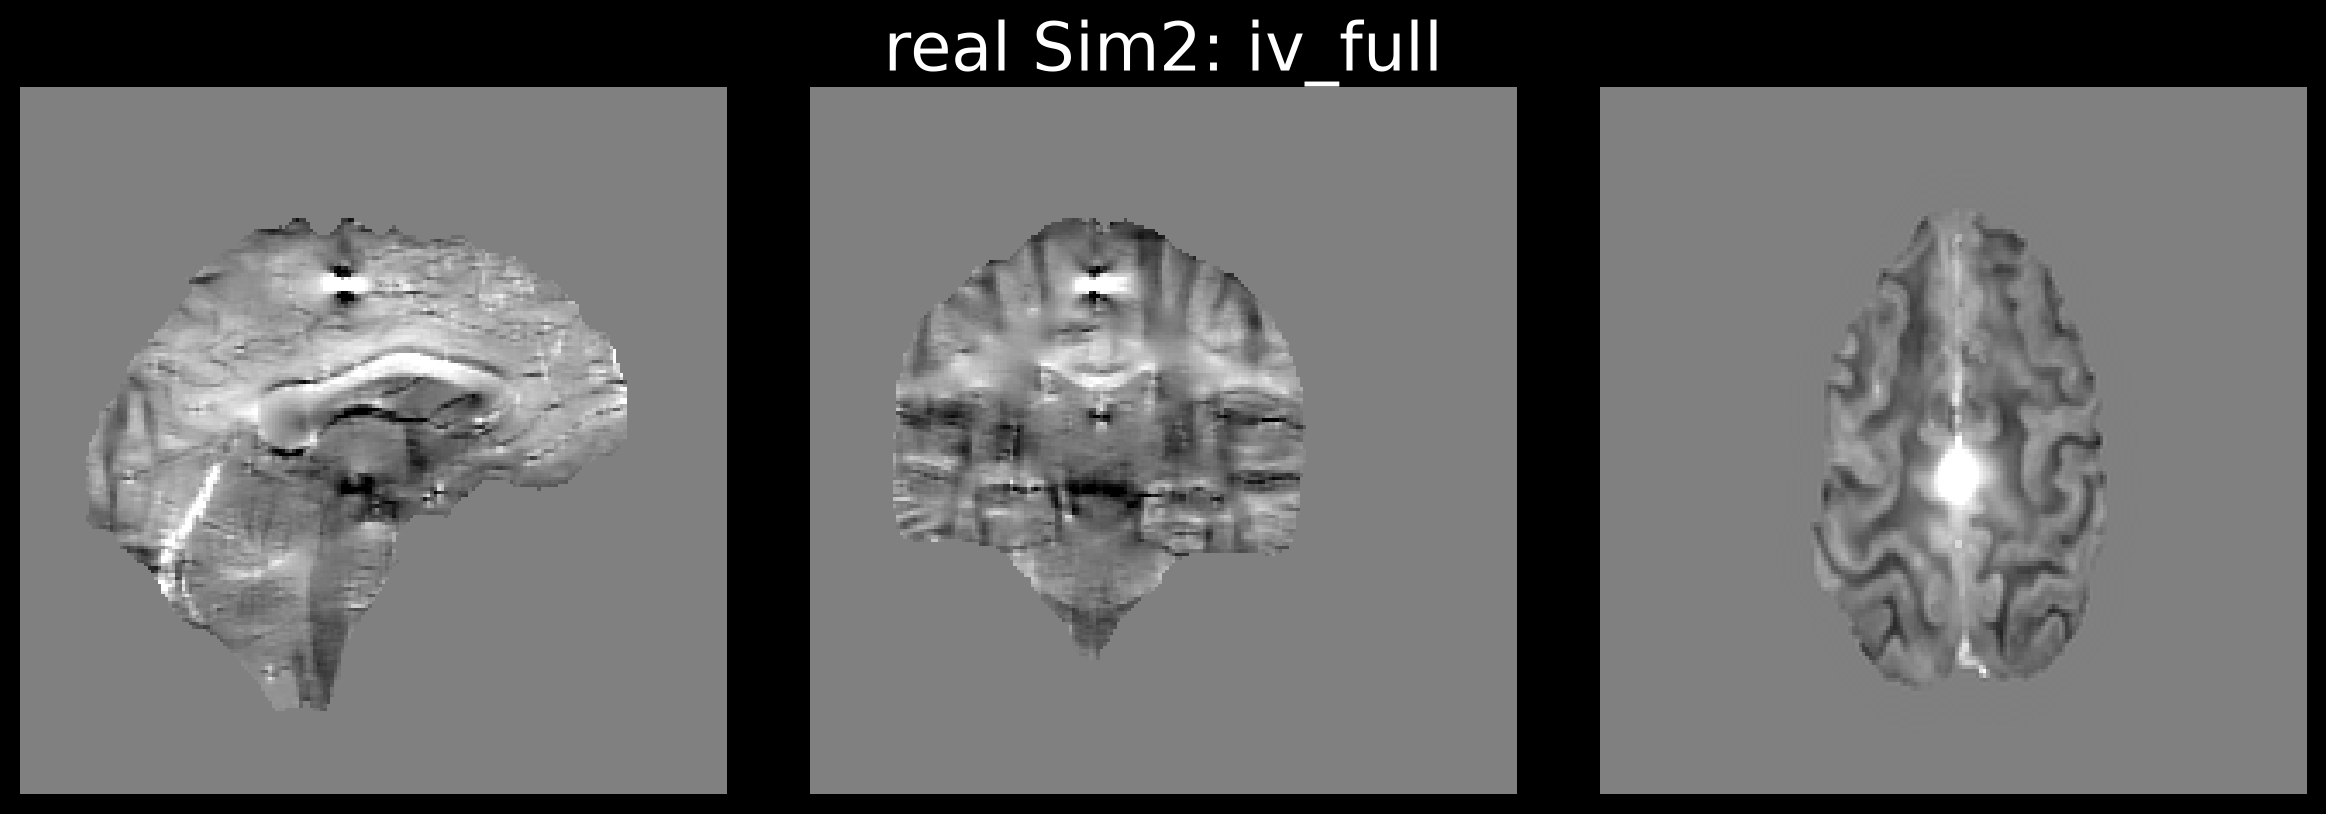

In [4]:
block('field', 'calc', ['real'], FIELD, 'field calc')

## 4. Other sets (edit the lists to see them)

In [5]:
# block('chi', 'centre', ['sim2_jumps', 'sim2_snr40'], CHI, 'chi centre')
# block('chi', 'calc', ['sim2_snrcal', 'sim2_snr40'], CHI, 'chi calc')

## 5. Scores (eNDI NRMSE %, 25 iterations, inside the brain mask)

In [6]:
print(f"{'set':32s}" + "".join(f"{m:>15s}" for m in METHODS))
for sname, label in LABEL.items():
    if f"nrmse/{sname}/dirty" in Z.files:
        print(f"{label:32s}" + "".join(f"{float(Z[f'nrmse/{sname}/{m}']):15.2f}" for m in METHODS))

set                                       dirty    noise_clean   iv_noisestat        iv_full
real Sim2                                 53.94          47.31          48.28          48.37
forward, SNR-cal noise                    67.31          47.61          48.18          48.38
forward, noise + phase jumps              67.25          48.56          48.99          50.95
forward, SNR 40                          121.84          52.36          52.09          52.36


## Honest limits
Single seed per network, one RC1 head, one Sim2 volume; a handful of planes is an illustration, not evidence (the numbers are in CLAUDE.md 9bp-bis).
The forward fields here use their own noise draw (a few tenths different from the scoring logs); only the real Sim2 row is identical to them.